# Sleep dynamics — run notebook

将本 notebook 放在服务器项目目录，将 `Sleep_NC_definitions.py` 放在项目的 `Code/` 子目录。
当前工作目录也应能找到原来的 `Code` 模块和数据目录。

所有函数定义已移入 `.py` 文件。先运行项目设置，再运行导入 cell；之后按原顺序运行计算和绘图。
`PROJECT_ROOT = Path.cwd()` 使用服务器当前工作目录。其余计算及绘图参数保留清理版原值。
主图 1–5、SI 图 1–5；SI 3b 使用 TV，SI 3c 使用 REM-containing flux loops。


In [1]:
from pathlib import Path
import os
import sys
import importlib
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Set this to the ORIGINAL project directory containing the data and Code module.
PROJECT_ROOT = Path.cwd()
# Leave None to use the original `from Code import *` dependency.
# If the original module is elsewhere, set its exact .py path here.
# A similarly named Codes.py is NOT silently substituted for Code.py.
EXTERNAL_CODE_FILE = None
FIGURE_OUTPUT_ROOT = PROJECT_ROOT / 'AllFiguresNapNoc_cleaned'

if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError(f'Set PROJECT_ROOT to the original project directory: {PROJECT_ROOT}')
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
# Support both the original Code dependency and definitions in Code/.
sys.path.append(str(PROJECT_ROOT / 'Code'))
if EXTERNAL_CODE_FILE is None:
    try:
        _external_code = importlib.import_module('Code')
    except ModuleNotFoundError as exc:
        if exc.name != 'Code':
            raise
        raise ModuleNotFoundError(
            'The original notebook depends on `from Code import *`. '
            'Set PROJECT_ROOT to that project, or set EXTERNAL_CODE_FILE to the original module. '
            'Code.py was not included in the supplied notebook; do not assume Codes.py is equivalent.'
        ) from exc
else:
    _external_path = Path(EXTERNAL_CODE_FILE).expanduser().resolve()
    _spec = importlib.util.spec_from_file_location('_original_sleep_code', _external_path)
    _external_code = importlib.util.module_from_spec(_spec)
    sys.modules[_spec.name] = _external_code
    _spec.loader.exec_module(_external_code)
_external_exports = getattr(_external_code, '__all__',
    [name for name in vars(_external_code) if not name.startswith('_')])
globals().update({name:getattr(_external_code,name) for name in _external_exports})
_required_helpers = ['load_sleepstageage','read_sc_subjects','compute_sleep_period_time',
    'leading_zeros_and_first_idx_np','count_transitions','count_transitions_to_zero',
    'compute_state_probabilities_list','fit_markov_chain','analyze_transition_matrices',
    'find_valid_flux_cycles','compute_J_matrix']
_missing_helpers = [name for name in _required_helpers if name not in globals()]
if _missing_helpers:
    raise ImportError('Original Code module is missing: '+', '.join(_missing_helpers))
_required_data = ['SleepStageAge_HypnogramData', 'SleepStageAge_HypnogramData/SC-subjects.xls',
    'PSG_Age', 'NewNapWei/Hypnograms/all_labels_dict.pkl']
_missing_paths = [str(PROJECT_ROOT/name) for name in _required_data if not (PROJECT_ROOT/name).exists()]
if _missing_paths:
    raise FileNotFoundError('Set PROJECT_ROOT; missing original data paths:\n'+'\n'.join(_missing_paths))
print('Project:',PROJECT_ROOT)
print('Original Code module:',getattr(_external_code,'__file__','<unknown>'))
print('Figure output:',FIGURE_OUTPUT_ROOT)

Project: /home/datadisk1/wxy/lfads-torch/tutorials/SleepStage
Original Code module: /home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/Code/__init__.py
Figure output: /home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned


In [2]:
# Load calculation and plotting definitions from the Code subfolder.
import sys
sys.path.append(str(PROJECT_ROOT / "Code"))
import Sleep_NC_definitions as sleep_defs
sleep_defs.configure_external_helpers(_external_code)
from Sleep_NC_definitions import *

print('Definitions loaded from:', sleep_defs.__file__)

Definitions loaded from: /home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/Code/Sleep_NC_definitions.py


## 1. Load and prepare nocturnal and nap hypnograms
保留原关灯时间修正、29 条 SOL 排除记录、缺失标签处理及截取边界。


In [3]:
all_epochs = load_sleepstageage("")
from pathlib import Path
import mne, datetime, pandas as pd

folder = Path("SleepStageAge_HypnogramData")
edf_files = sorted(folder.glob("*.edf"))

rows = []
for fp in edf_files:
    try:
        raw = mne.io.read_raw_edf(str(fp), preload=False, verbose=False)

        # 绝对起始时刻优先级：annotations.orig_time > info["meas_date"]
        meas_date = raw.info.get("meas_date", None)  # UTC datetime 或 None
        anno_origin = getattr(raw.annotations, "orig_time", None) if hasattr(raw, "annotations") else None
        start_dt = anno_origin if anno_origin is not None else meas_date

        # 记录时长与结束时间（若能确定起点与时长）
        duration_s = float(raw.times[-1]) if raw.n_times > 0 else None
        end_dt = (start_dt + datetime.timedelta(seconds=duration_s)) if (start_dt and duration_s is not None) else None

        rows.append({
            "file": fp.name,
            "start_utc": start_dt,          # 通常为 UTC
            "duration_s": duration_s,
            "end_utc": end_dt
        })
    except Exception as e:
        rows.append({
            "file": fp.name,
            "start_utc": None,
            "duration_s": None,
            "end_utc": None,
            "error": str(e)
        })
from pathlib import Path
from typing import Union, Dict
import pandas as pd

# 确保上面的函数 read_sc_subjects 已定义
sheets = read_sc_subjects("SleepStageAge_HypnogramData/SC-subjects.xls")  # 或 "SC-subjects.xlsx"

print(list(sheets.keys()))        # 查看有哪些工作表
from pathlib import Path
from typing import Union, Dict
import pandas as pd

# 确保上面的函数 read_sc_subjects 已定义
print(list(sheets.keys()))        # 查看有哪些工作表

AllAges = []
for i in range(153):
    AllAges.append(sheets['Blad1']['age'][i])
AllAges = np.array(AllAges)

# ====== rows 统一成 DataFrame ======
rows_df = pd.DataFrame(rows) if isinstance(rows, list) else rows.copy()
# ====== 对每个 i 计算关灯 epoch_idx ======
lights_off_epoch = []
for i in range(len(all_epochs)):
    df_i = all_epochs[i]
    start_dt = rows_df.loc[i, "start_utc"]          # ✅ 修正：不要用 rows[i]["start_utc"]
    lights_off_val = sheets["Blad1"]["LightsOff"].iloc[i]

    idx = lights_off_epoch_idx_by_tstart_end(df_i, start_dt, lights_off_val)
    idx_30s = idx * (all_epochs[i]['epoch_sec'][0]/30)
    lights_off_epoch.append(idx_30s)

AllLOffIdx = np.asarray(lights_off_epoch, dtype=int)  # 若含 None 会变成 nan

/home/datadisk1/wxy/jupyter_notebook/tmp/ipykernel_1531680/1238210123.py:11: RuntimeWarning: Header information is incorrect for record length. Default record length set to 1.
It is possible that this file only contains annotations and no signals. In that case, please use mne.read_annotations() to load these annotations.
  raw = mne.io.read_raw_edf(str(fp), preload=False, verbose=False)
/home/datadisk1/wxy/jupyter_notebook/tmp/ipykernel_1531680/1238210123.py:11: RuntimeWarning: Omitted 153 annotation(s) that were outside data range.
  raw = mne.io.read_raw_edf(str(fp), preload=False, verbose=False)
/home/datadisk1/wxy/jupyter_notebook/tmp/ipykernel_1531680/1238210123.py:11: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_edf(str(fp), preload=False, verbose=False)
/home/datadisk1/wxy/jupyter_notebook/tmp/ipykernel_1531680/1238210123.py:11: RuntimeWarning: Header information is incorrect for record length. Default record length 

['Blad1', 'Blad2', 'Blad3']
['Blad1', 'Blad2', 'Blad3']


In [4]:
import re
from pathlib import Path
import pandas as pd

# EDF 文件顺序
folder = Path("SleepStageAge_HypnogramData")

edf_files = sorted(
    fp for fp in folder.glob("*.edf")
    if "hypnogram" in fp.name.lower()
)

edf_order = [
    parse_sc_filename(fp.name)
    for fp in edf_files
]


# Excel 顺序
meta_df = sheets["Blad1"].copy()

excel_order = list(
    zip(
        pd.to_numeric(
            meta_df["subject"],
            errors="raise",
        ).astype(int),

        pd.to_numeric(
            meta_df["night"],
            errors="raise",
        ).astype(int),
    )
)


print("EDF 数量：", len(edf_order))
print("Excel 行数：", len(excel_order))
print("EDF 与 Excel 顺序完全一致：", edf_order == excel_order)


# 如果不一致，显示错位位置
if edf_order != excel_order:
    for i, (edf_key, excel_key) in enumerate(
        zip(edf_order, excel_order)
    ):
        if edf_key != excel_key:
            print(
                f"第 {i} 个位置不一致："
                f"EDF={edf_key}, Excel={excel_key}, "
                f"file={edf_files[i].name}"
            )

EDF 数量： 153
Excel 行数： 153
EDF 与 Excel 顺序完全一致： True


In [5]:
AllLabels = []

for i in range(153):

    stage_seg = all_epochs[i]["stage"]       # 每段一个标签
    epoch_sec = all_epochs[i]["epoch_sec"]   # 每段持续秒数
    
    hyp_name = all_epochs[i]["file_name"][0]
    print(hyp_name)
    base = hyp_name.removesuffix("-Hypnogram.edf")  # "SC4051EC"
    PSGname = base[:-1] + "0-PSG.edf"               # 把最后那个字母换成0
    
    y = load_psg_y_only(
        psg_dir="PSG_Age",
        target_name=PSGname,
        stage_seg=all_epochs[i]["stage"],
        epoch_sec=all_epochs[i]["epoch_sec"],
        base_sec=30.0,
        include_tail=False,
    )
    print(y.shape)
    AllLabels.append(y)

SC4001EC-Hypnogram.edf
(2650,)
SC4002EC-Hypnogram.edf
(2830,)
SC4011EH-Hypnogram.edf
(2802,)
SC4012EC-Hypnogram.edf
(2848,)
SC4021EH-Hypnogram.edf
(2804,)
SC4022EJ-Hypnogram.edf
(2754,)
SC4031EC-Hypnogram.edf
(2820,)
SC4032EP-Hypnogram.edf
(2732,)
SC4041EC-Hypnogram.edf
(2202,)
SC4042EC-Hypnogram.edf
(2790,)
SC4051EC-Hypnogram.edf
(2722,)
SC4052EC-Hypnogram.edf
(2805,)
SC4061EC-Hypnogram.edf
(2770,)
SC4062EC-Hypnogram.edf
(2828,)
SC4071EC-Hypnogram.edf
(2808,)
SC4072EH-Hypnogram.edf
(2770,)
SC4081EC-Hypnogram.edf
(2796,)
SC4082EP-Hypnogram.edf
(2634,)
SC4091EC-Hypnogram.edf
(2730,)
SC4092EC-Hypnogram.edf
(2052,)
SC4101EC-Hypnogram.edf
(2720,)
SC4102EC-Hypnogram.edf
(2858,)
SC4111EC-Hypnogram.edf
(2642,)
SC4112EC-Hypnogram.edf
(2780,)
SC4121EC-Hypnogram.edf
(2684,)
SC4122EV-Hypnogram.edf
(2606,)
SC4131EC-Hypnogram.edf
(2814,)
SC4141EU-Hypnogram.edf
(2756,)
SC4142EU-Hypnogram.edf
(2774,)
SC4151EC-Hypnogram.edf
(2620,)
SC4152EC-Hypnogram.edf
(2864,)
SC4161EC-Hypnogram.edf
(2625,)
SC4162EC

In [6]:
import numpy as np

# idx: LOIdx 映射
updates = {
    4: 0,
    8: 0,
    19: 0,
    24: 0,
    36: 0,
    43: 0,
    48: 600,
    53: 0,
    58: 600,
    66: 0,
    67: 0,
    75: 600,
    76: 0,
    88: 0,
    89: 0,
    91: 0,
    93: 0,
    100: 0,
    106: 0,
    118: 0,
    119: 0,
    120: 0,
    121: 0,
    122: 0,
    125: 900,
    126: 840,
    133: 0,
    134: 0,
    149: 0,
}

# 确保是 numpy array，且可写
AllLOffIdx = np.asarray(AllLOffIdx).copy()

# 只改指定 idx，其它不变
for idx, lo in updates.items():
    AllLOffIdx[idx] = lo

# 可选：打印确认
print("已更新的 idx:", sorted(updates.keys()))
print("对应的新值:", [AllLOffIdx[i] for i in sorted(updates.keys())])

已更新的 idx: [4, 8, 19, 24, 36, 43, 48, 53, 58, 66, 67, 75, 76, 88, 89, 91, 93, 100, 106, 118, 119, 120, 121, 122, 125, 126, 133, 134, 149]
对应的新值: [0, 0, 0, 0, 0, 0, 600, 0, 600, 0, 0, 600, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 900, 840, 0, 0, 0]


In [7]:
AllSleepLength = []
AllLastIdx = []
AllFirstIdx = []

for i in range(len(all_epochs)):
    res = compute_sleep_period_time(
    AllLabels[i][AllLOffIdx[i]:],
    epoch_sec=30, #all_epochs[i]['epoch_sec'][0],                     # 你这批数据是 60s 一个 epoch
    max_wake_gap_sec=3*3600,
    wake_values={0, "W", "Wake"},     # 按你的编码调整
    missing_values={"?", None, "NaN"} # 未测
)
    AllSleepLength.append(res['spt_minutes'])
    AllLastIdx.append(res['last_sleep_idx'])
    AllFirstIdx.append(res['first_sleep_idx'])

AllSleepLength = np.array(AllSleepLength)
AllLastIdx = np.array(AllLastIdx)
AllFirstIdx = np.array(AllFirstIdx)
NocTST = np.array(AllSleepLength)

In [8]:
AllSleepStages = {}

for i in range(153):
    # AllSleepStages[i] = np.array(all_epochs[i]["stage"][AllLOffIdx[i]:AllLastIdx[i]+AllLOffIdx[i]].tolist())
    AllSleepStages[i] = np.array(AllLabels[i][AllLOffIdx[i]:AllLastIdx[i]+AllLOffIdx[i]+2].tolist())

In [9]:
# print(leading_zeros_and_first_idx_np(AllSleepStages))
SOL = first_passage_counts_array(
    AllSleepStages,
    target_state='W',       # wake
    mode="leave",         # 首次离开 wake
    tol=0.0,
)

SOL_idx = np.array(SOL)
FinalSOL = []
LOInSleep = [4, 8, 19, 24, 36, 43, 48, 53, 58, 66, 67, 75, 76, 88, 89, 91, 93, 100, 106, 118, 119, 120, 121, 122, 125, 126, 133, 134, 149]

for i in range(153):
    if i in LOInSleep:
        continue
    FinalSOL.append(SOL_idx[i] * 30 / 60)
FinalSOL = np.array(FinalSOL)

In [10]:
import numpy as np
import pandas as pd

AllHypDict = {}
for i in range(len(all_epochs)):
    s = AllLabels[i] #all_epochs[i]["stage"]  # 一列，长度比如 1440
    s = pd.Series(s)

    # 先标准化成小写字符串
    s_norm = s.astype(str).str.strip().str.lower()

    # ① 把 "?" 变成 NaN，方便用前向填充
    s_clean = s_norm.replace("?", np.nan)

    # ② 先用前一个值填（你要的规则）
    s_clean = s_clean.ffill()

    # ③ 如果开头本来就是 "?"，ffill 填不上，就再用后一个值来补一下
    s_clean = s_clean.bfill()

    # 映射表
    mapper = {
        "w": 0, "wake": 0,
        "n1": 1, "1": 1,
        "n2": 2, "2": 2,
        "n3": 3, "3": 3,
        # "n4": 4, "4": 4,
        "rem": 4, "r": 4,
    }

    # 映射成数字；没在表里的会变成 NaN
    arr_stage = s_clean.map(mapper).to_numpy()

    # 截出你要的有效段
    if i in LOInSleep:
        arr_stage = arr_stage[AllLOffIdx[i]+AllFirstIdx[i]-1 : AllLOffIdx[i]+AllLastIdx[i]+2] #+AllFirstIdx[i]
    else:
        arr_stage = arr_stage[AllLOffIdx[i]-1 : AllLOffIdx[i]+AllLastIdx[i]+2] #+AllFirstIdx[i]

    AllHypDict[i] = arr_stage

    # 可选：看看还有没有没映射到的标签
    unknown = sorted(set(s_clean.unique()) - set(mapper.keys()))
    if unknown:
        print(f"Unmapped labels in {i}:", unknown)

In [17]:
import pickle

# 替换为你的文件路径
file_path = 'NewNapWei/Hypnograms/all_labels_dict.pkl' #"../../datasets/sleep_stage_nap.pickle" #

with open(file_path, "rb") as f:
    data = pickle.load(f)
NapHyp = data

In [18]:
SOL = leading_zeros_and_first_idx_np(NapHyp)
SOL = np.array([SOL[k]['leading_zeros'] for k in sorted(SOL.keys())])
NapSOL = SOL

In [19]:
AllTransNum = []

for i in range(24):
    counts, counts_df = count_transitions(NapHyp[i], states=[0,1,2,3,4], include_self=False)
    AllTransNum.append(counts.sum())
NapTransNum = np.array(AllTransNum)

NapProbs = compute_state_probabilities_list(NapHyp)

AllSleepLength = []
for i in range(24):
    res = compute_sleep_period_time(
        NapHyp[i],
        epoch_sec=30,
        max_wake_gap_sec=1*3600,
        wake_values={"0", "W", "Wake"},     # 按你的编码调整
        missing_values={"?", None, "NaN"} # 未测
    )
    AllSleepLength.append(res['spt_minutes'])
NapTST = np.array(AllSleepLength)

AllToWakeNum = []
for n in range(24):
    to_zero_count = count_transitions_to_zero(NapHyp[n], 0)
    AllToWakeNum.append(to_zero_count)
NapToWakeNum = np.array(AllToWakeNum)

In [20]:
NocSOL = FinalSOL
NocHypDict = AllHypDict

AllToWakeNum = []
for n in range(153):
    to_zero_count = count_transitions_to_zero(AllHypDict[n], 0)
    AllToWakeNum.append(to_zero_count)
NocToWakeNum = np.array(AllToWakeNum)

AllTransNum = []
for i in range(153):
    counts, counts_df = count_transitions(AllSleepStages[i], states=['W','N1','N2','N3','REM'], include_self=False)
    AllTransNum.append(counts.sum())
NocTransNum = np.array(AllTransNum)

NocProbs = compute_state_probabilities_list(AllHypDict, num_states=5)

## 2. Temporal cycles, transition matrices and driving forces
原计算函数只保留最终图实际依赖的定义；loop counts 仍按真实时序循环计数，不替换成分解得到的 flux-loop 数量。


In [21]:
results = find_all_temporal_cycles_all_subjects(
    data=NocHypDict,
    compress_consecutive=True,
    min_distinct_states=3,
    max_distinct_states=5,
    merge_reverse=False,
    epoch_sec=30,
)
Noc_df_occ = occurrences_to_dataframe(results)
Noc_df_cycles = cycles_to_dataframe(results)

results = find_all_temporal_cycles_all_subjects(
    data=NapHyp,
    compress_consecutive=True,
    min_distinct_states=3,
    max_distinct_states=5,
    merge_reverse=False,
    epoch_sec=30,
)
Nap_df_occ = occurrences_to_dataframe(results)
Nap_df_cycles = cycles_to_dataframe(results)

In [22]:
results, df_summary = count_total_loops_all_subjects(
    data=NocHypDict,
    compress_consecutive=True,
    min_distinct_states=3,   # 至少3个不同状态才算 loop
    max_distinct_states=5,   # 5-state sleep
)

Noc_loop_counts = df_summary["total_loop_occurrences"].to_numpy()
Noc_Sub_Loop_Dur = df_summary["mean_cycle_duration"]/30

results, df_summary = count_total_loops_all_subjects(
    data=NapHyp,
    compress_consecutive=True,
    min_distinct_states=3,   # 至少3个不同状态才算 loop
    max_distinct_states=5,   # 5-state sleep
)

Nap_loop_counts = df_summary["total_loop_occurrences"].to_numpy()
Nap_Sub_Loop_Dur = df_summary["mean_cycle_duration"]/30

In [23]:
Tmat = []
for tr in range(153):
    # print('people number =', tr)
    state_seq = AllHypDict[tr]
    train_seq_len = int(1.0*state_seq.shape[0])
    mat = fit_markov_chain(state_seq[:train_seq_len], n_states=5, plot=False) #
    Tmat.append(mat)
NocTmat = Tmat

In [24]:
# 例如有个状态序列
Tmat_ori = []
for tr in range(24):
    # print('people number =', tr)
    state_seq = NapHyp[tr]

    train_seq_len = int(1*state_seq.shape[0])
    mat = fit_markov_chain(state_seq[:train_seq_len], n_states=5, plot=False) #
    Tmat_ori.append(mat)

NapTmat = Tmat_ori

In [25]:
eps = 1e-10
NocPss, NocSss, NocFss, NocFS, NocAss, NocJss, NocEPRss = analyze_transition_matrices(NocTmat, plot=False, probs=None, eps=eps)
NocAllCycle, NocAllStrength, NocAllEPR = find_valid_flux_cycles(NocFS, NocAss, NocJss, eps=eps)
AllTotalFlux = []
for i in range(153):
    AllTotalFlux.append(np.array(NocAllStrength[i]).sum())
NocTotalFlux = np.array(AllTotalFlux)
AllWakeCycleStrength = [
    sum(
        st for cyc, st in zip(NocAllCycle.get(k, []), NocAllStrength.get(k, []))
        if 0 in cyc
    )
    for k in range(153)   # 0~21
]
NocWakeCycleStrength = np.array(AllWakeCycleStrength)

NapPss, NapSss, NapFss, NapFS, NapAss, NapJss, NapEPRss = analyze_transition_matrices(NapTmat, plot=False, probs=None, eps=eps)
NapAllCycle, NapAllStrength, NapAllEPR = find_valid_flux_cycles(NapFS, NapAss, NapJss, eps=eps)
AllTotalFlux = []
for i in range(24):
    AllTotalFlux.append(np.array(NapAllStrength[i]).sum())
NapTotalFlux = np.array(AllTotalFlux)
AllWakeCycleStrength = [
    sum(
        st for cyc, st in zip(NapAllCycle.get(k, []), NapAllStrength.get(k, []))
        if 0 in cyc
    )
    for k in range(24)   # 0~21
]
NapWakeCycleStrength = np.array(AllWakeCycleStrength)

[1. 1. 1. 1. 1.]
[Matrix 0] P (steady-state) = ['9.57e-02', '7.62e-02', '3.52e-01', '3.05e-01', '1.72e-01']
[Matrix 0] S = ['2.25e-01', '1.96e-01', '3.68e-01', '3.62e-01', '3.03e-01']
[Matrix 0] EPR = 1.79e-01
[1. 1. 1. 1. 1.]
[Matrix 1] P (steady-state) = ['6.98e-02', '5.90e-02', '3.64e-01', '3.02e-01', '2.06e-01']
[Matrix 1] S = ['1.86e-01', '1.67e-01', '3.68e-01', '3.61e-01', '3.25e-01']
[Matrix 1] EPR = 1.50e-01
[1. 1. 1. 1. 1.]
[Matrix 2] P (steady-state) = ['3.38e-02', '9.83e-02', '5.68e-01', '1.01e-01', '1.99e-01']
[Matrix 2] S = ['1.14e-01', '2.28e-01', '3.21e-01', '2.31e-01', '3.22e-01']
[Matrix 2] EPR = 7.40e-02
[1. 1. 1. 1. 1.]
[Matrix 3] P (steady-state) = ['4.18e-02', '9.14e-02', '6.14e-01', '8.99e-02', '1.63e-01']
[Matrix 3] S = ['1.33e-01', '2.19e-01', '3.00e-01', '2.17e-01', '2.96e-01']
[Matrix 3] EPR = 5.24e-02
[1. 1. 1. 1. 1.]
[Matrix 4] P (steady-state) = ['1.23e-02', '1.07e-01', '6.11e-01', '9.93e-02', '1.70e-01']
[Matrix 4] S = ['5.42e-02', '2.39e-01', '3.01e-01', 

In [26]:
NocFlux_list, NocFlux_sym_list, NocFlux_irr_list = decompose_flux_lists(
    NocPss, NocTmat, mode='loop', zero_diag=True
)

NocAllSymFlux = []
NocAllSymFluxToWake = []
NocAllLoopFlux = []
NocAllLoopFluxToN3 = []

for i in range(153):
    NocAllSymFlux.append(NocFlux_sym_list[i].sum())
    NocAllSymFluxToWake.append(NocFlux_sym_list[i][:, 0].sum())
    NocAllLoopFlux.append(NocFlux_irr_list[i].sum())
    NocAllLoopFluxToN3.append(NocFlux_irr_list[i][:, 4].sum())
NocAllSymFlux = np.array(NocAllSymFlux)
NocAllSymFluxToWake = np.array(NocAllSymFluxToWake)
NocAllLoopFluxToN3 = np.array(NocAllLoopFluxToN3)
NocAllLoopFlux = np.array(NocAllLoopFlux)

NocAllNoDiagT = []
NocAllNoDiagT_ForSOL = []
NocAllNoDiagTWake = []

for i in range(153):
    NocAllNoDiagT.append(NocTmat[i].sum() - np.trace(NocTmat[i]))
    NocAllNoDiagTWake.append(NocTmat[i][:, 0].sum() - NocTmat[i][0, 0])

for i in range(153):
    if i in LOInSleep:
        continue
    NocAllNoDiagT_ForSOL.append(NocTmat[i][0, 1:].sum())

NocAllNoDiagT_ForSOL = np.array(NocAllNoDiagT_ForSOL)
NocAllNoDiagT = np.array(NocAllNoDiagT)
NocAllNoDiagTWake = np.array(NocAllNoDiagTWake)

In [27]:
NapFlux_list, NapFlux_sym_list, NapFlux_irr_list = decompose_flux_lists(
    NapPss, NapTmat, mode='loop', zero_diag=True
)

NapAllSymFlux = []
NapAllSymFluxToWake = []
NapAllLoopFlux = []
NapAllLoopFluxToN3 = []   # 新增：irreversible loop flux flowing into N3

for i in range(24):
    NapAllSymFlux.append(NapFlux_sym_list[i].sum())
    NapAllSymFluxToWake.append(NapFlux_sym_list[i][:, 0].sum())

    NapAllLoopFlux.append(NapFlux_irr_list[i].sum())
    NapAllLoopFluxToN3.append(NapFlux_irr_list[i][:, 4].sum())  # 新增

NapAllSymFlux = np.array(NapAllSymFlux)
NapAllSymFluxToWake = np.array(NapAllSymFluxToWake)
NapAllLoopFlux = np.array(NapAllLoopFlux)
NapAllLoopFluxToN3 = np.array(NapAllLoopFluxToN3)   # 新增

NapAllNoDiagT = []
NapAllNoDiagT_ForSOL = []
NapAllNoDiagTWake = []

for i in range(24):
    NapAllNoDiagT.append(NapTmat[i].sum() - np.trace(NapTmat[i]))
    NapAllNoDiagTWake.append(NapTmat[i][:, 0].sum() - NapTmat[i][0, 0])
for i in range(24):
    NapAllNoDiagT_ForSOL.append(NapTmat[i][0, 1:].sum())

NapAllNoDiagT_ForSOL = np.array(NapAllNoDiagT_ForSOL)
NapAllNoDiagT = np.array(NapAllNoDiagT)
NapAllNoDiagTWake = np.array(NapAllNoDiagTWake)


In [28]:
Noc_per_subject_sum, Noc_per_subject_detail = sum_nrem_rem_flux(NocAllCycle, NocAllStrength) #AllEPR

subject_ids = sorted(Noc_per_subject_sum.keys())
Noc_nrem_rem_flux_sum = np.array([Noc_per_subject_sum[s] for s in subject_ids])

NocAllSymFlux_REMNREM = []
NocAllSymFlux_N2N3 = []
NocAllFlux_N2N3 = []
NocAllLoopFlux_N2N3 = []
NocAllNoDiagT_REMNREM = []

for i in range(153):
    NocAllSymFlux_REMNREM.append(NocFlux_sym_list[i][1:4, 4].sum() + NocFlux_sym_list[i][4, 1:4].sum())
    NocAllSymFlux_N2N3.append(NocFlux_sym_list[i][2, 3] + NocFlux_sym_list[i][3, 2])
    NocAllFlux_N2N3.append(NocFlux_list[i][2, 3] + NocFlux_list[i][3, 2])
    NocAllLoopFlux_N2N3.append(NocFlux_irr_list[i][2, 3] + NocFlux_irr_list[i][3, 2])
    NocAllNoDiagT_REMNREM.append(NocTmat[i][1:4, 4].sum() + NocTmat[i][4, 1:4].sum())
    
NocAllSymFlux_REMNREM = np.array(NocAllSymFlux_REMNREM)
NocAllNoDiagT_REMNREM = np.array(NocAllNoDiagT_REMNREM)
NocAllSymFlux_N2N3 = np.array(NocAllSymFlux_N2N3)
NocAllFlux_N2N3 = np.array(NocAllFlux_N2N3)
NocAllLoopFlux_N2N3 = np.array(NocAllLoopFlux_N2N3)


In [29]:
Noc_N2N3_freq = compute_N2_N3_transition_frequency(NocHypDict)


### 2.1 Early sleep-onset driving forces
沿用原先前 20 步（10 min）取平均的定义。删除后续 180 步、未被最终图使用的瞬态 EPR 和逐步循环枚举；不改变使用的 20 个概率分布。


In [30]:

NocInitialFlux, NocInitialSymFlux = _early_sleep_forces(
    NocTmat, [i for i in range(153) if i not in LOInSleep])
NapInitialFlux, NapInitialSymFlux = _early_sleep_forces(NapTmat, range(24))


## 3. Inside/outside occurrence tables and REM-containing loop matrix
Inside/outside 使用原 cell 59 的参数，包括 min_nrem_min=0、min_rem_min=0 和 REM-loop 强制 inside 规则。示意图的 15/5 min 标记阈值仍按原最终绘图参数保留，两处定义不同，未悄悄统一。


In [31]:
out_inside_outside_tests = analyze_inside_outside_duration_significance_by_category(
    data=NocHypDict,
    AllCycle=NocAllCycle,

    epoch_sec=30,

    wake_state=0,
    rem_state=4,
    nrem_states=(1, 2, 3),

    min_nrem_min=0,
    min_rem_min=0,

    include_post_rem_state=True,
    include_wake_in_structure=True,

    inside_uses_structure_end=True,

    # 实际观测到的完整 AllCycle loop 片段包含 REM -> loop 强制 inside
    rem_observed_loop_counts_as_inside=True,

    # None = 整个 hypnogram 所有未被 loop 覆盖的 transition edges 都算 reversible
    reversible_states=None,

    count_open_alternating_blocks=True,

    min_n_per_group=3,
    alpha=0.05,
)

df_nremrem_intervals = out_inside_outside_tests["df_nremrem_intervals"]
df_reversible_occurrence = out_inside_outside_tests["df_reversible_occurrence"]
df_loop_occurrence = out_inside_outside_tests["df_loop_occurrence"]


In [32]:
# Preserve the original REM + NREM loop selection; no cycle-coverage filtering.
Noc_loop_matrix = build_loop_strength_matrix(
    Noc_per_subject_detail,
    merge_rotations=True,
    merge_reverse=False,
)


## 4. Flux removal and simulations
保留每条记录 100 次模拟、初始状态 Wake、base_seed=1234、时长 TST×2 epochs 和原 k 网格。该部分可能耗时较长。


In [33]:
Noc_T_eq_list, Noc_details_eq = modify_loops_and_reconstruct_Ts(
    NocJss, NocTmat, remove_all_loops=True, return_details=True
)

Noc_sim_data = generate_simulated_hypnogram_data(
    T_new_list=Noc_T_eq_list,
    Tmat=NocTmat,
    AllSleepLength=NocTST*2,
    n_sims=100,
    init_state=0,
    base_seed=1234,
    tol=1e-12,
    simulate_orig_when_new_none=False,
)

In [34]:
k_values = np.arange(0, 5 + 1e-9, 0.1)

Noc_results_by_k, Noc_df_subject_k, Noc_df_k_summary = analyze_simulated_data_over_k(
    sim_data=Noc_sim_data,
    k_values=k_values,
    epoch_sec=30,
    wake_state=0,
    rem_state=4,
    nrem_states=(1, 2, 3),
    count_after_sleep_onset=True,
    wake_breaks_cycle=True,
    min_unique_states_for_loop=3,
    as_list=True,
)

In [37]:
Nap_T_eq_list, Nap_details_eq = modify_loops_and_reconstruct_Ts(
    NapJss, NapTmat, remove_all_loops=True, return_details=True
)

Nap_sim_data = generate_simulated_hypnogram_data(
    T_new_list=Nap_T_eq_list,
    Tmat=NapTmat,
    AllSleepLength=NapTST*2,
    n_sims=100,
    init_state=0,
    base_seed=1234,
    tol=1e-12,
    simulate_orig_when_new_none=False,
)

In [38]:
k_values = np.arange(0, 5 + 1e-9, 0.1)

Nap_results_by_k, Nap_df_subject_k, Nap_df_k_summary = analyze_simulated_data_over_k(
    sim_data=Nap_sim_data,
    k_values=k_values,
    epoch_sec=30,
    wake_state=0,
    rem_state=4,
    nrem_states=(1, 2, 3),
    count_after_sleep_onset=True,
    wake_breaks_cycle=True,
    min_unique_states_for_loop=3,
    as_list=True,
)

## 5. Probability relaxation — TV distance
经用户确认，两组均使用 $D_{TV}(t)=\frac12\sum_i|P_i(t)-P_i^{ss}|$。原 max_abs 结果不再用于 SI 3b，必须运行此节重新生成。threshold=0.1 和原演化时间范围保留。


In [39]:
Noc_df_steady = compare_steady_time_for_Tnew_and_Tmat(
    T_new_list=Noc_T_eq_list,
    Tmat=NocTmat,
    Pss_list=NocPss,
    AllSleepLength=NocTST * 2,
    init_state=0,
    threshold=0.1,
    consecutive=1,
    metric="tv",
)


In [40]:
Nap_df_steady = compare_steady_time_for_Tnew_and_Tmat(
    T_new_list=Nap_T_eq_list,
    Tmat=NapTmat,
    Pss_list=NapPss,
    AllSleepLength=NapTST * 2,
    init_state=0,
    threshold=0.1,
    consecutive=1,
    metric="tv",
)


In [41]:
# Verify the meaning of the stored series before plotting it as TV.
for _cohort, _table in [('Nocturnal', Noc_df_steady), ('Nap', Nap_df_steady)]:
    for _record in _table.itertuples():
        _probabilities = np.asarray(_record.probability_series, dtype=float)
        _expected_tv = 0.5 * np.abs(_probabilities - np.asarray(_record.Pss)).sum(axis=1)
        if not np.allclose(_record.distance_series, _expected_tv, rtol=1e-10, atol=1e-12):
            raise ValueError(f'{_cohort}: distance_series does not contain TV distance.')
print('Verified: both probability-relaxation tables contain TV distance.')


Verified: both probability-relaxation tables contain TV distance.


## 6. Final main figures
只保留原文件中的最终 def/run。各图的参数仍放在自己的 run cell；输出集中到 `FIGURE_OUTPUT_ROOT`。


### Main Fig. 1


/home/datadisk1/wxy/jupyter_notebook/tmp/ipykernel_1531680/727968156.py:14: UserWarning: T has 0 nonstochastic positive rows and 26 zero rows. All supplied values are retained without renormalization.
  fig1 = plot_sleep_fig1(


Individual matrix counts: {'NapTmat': 24, 'NocTmat': 153, 'NapFS': 24, 'NocFS': 153, 'T_total': 177, 'Q_total': 177}
Illustrative sequence metadata: {'type': 'illustrative random examples, not excerpts from panel a', 'seed': 2026, 'examples': [['R', 'W', 'W', 'N3', 'N1'], ['N2', 'W', 'N1', 'N3', 'N1'], ['R', 'N3', 'N3', 'R', 'N3']], 'displayed_count': 3, 'collection_continues': True}
Hypnocycle source: {'match_count': 4, 'selected_match': 0, 'start_epoch': 589, 'return_epoch': 673, 'stop_epoch_exclusive': 674, 'time_h': [4.908333333333333, 5.616666666666666], 'compressed_labels': ['N2', 'WAKE', 'N1', 'N2']}
Timing annotations: {'lights_off_epoch': 0, 'sleep_onset_epoch': 13, 'sleep_offset_epoch': 945, 'sleep_offset_source': 'terminal Wake after last scored sleep', 'SOL_seconds': 390.0, 'onset_definition': 'first scored non-Wake epoch at/after lights off unless explicitly supplied', 'lights_off_source': 'explicitly supplied', 'transition_epoch': 509, 'awakening_epoch': 909, 'falling_asl

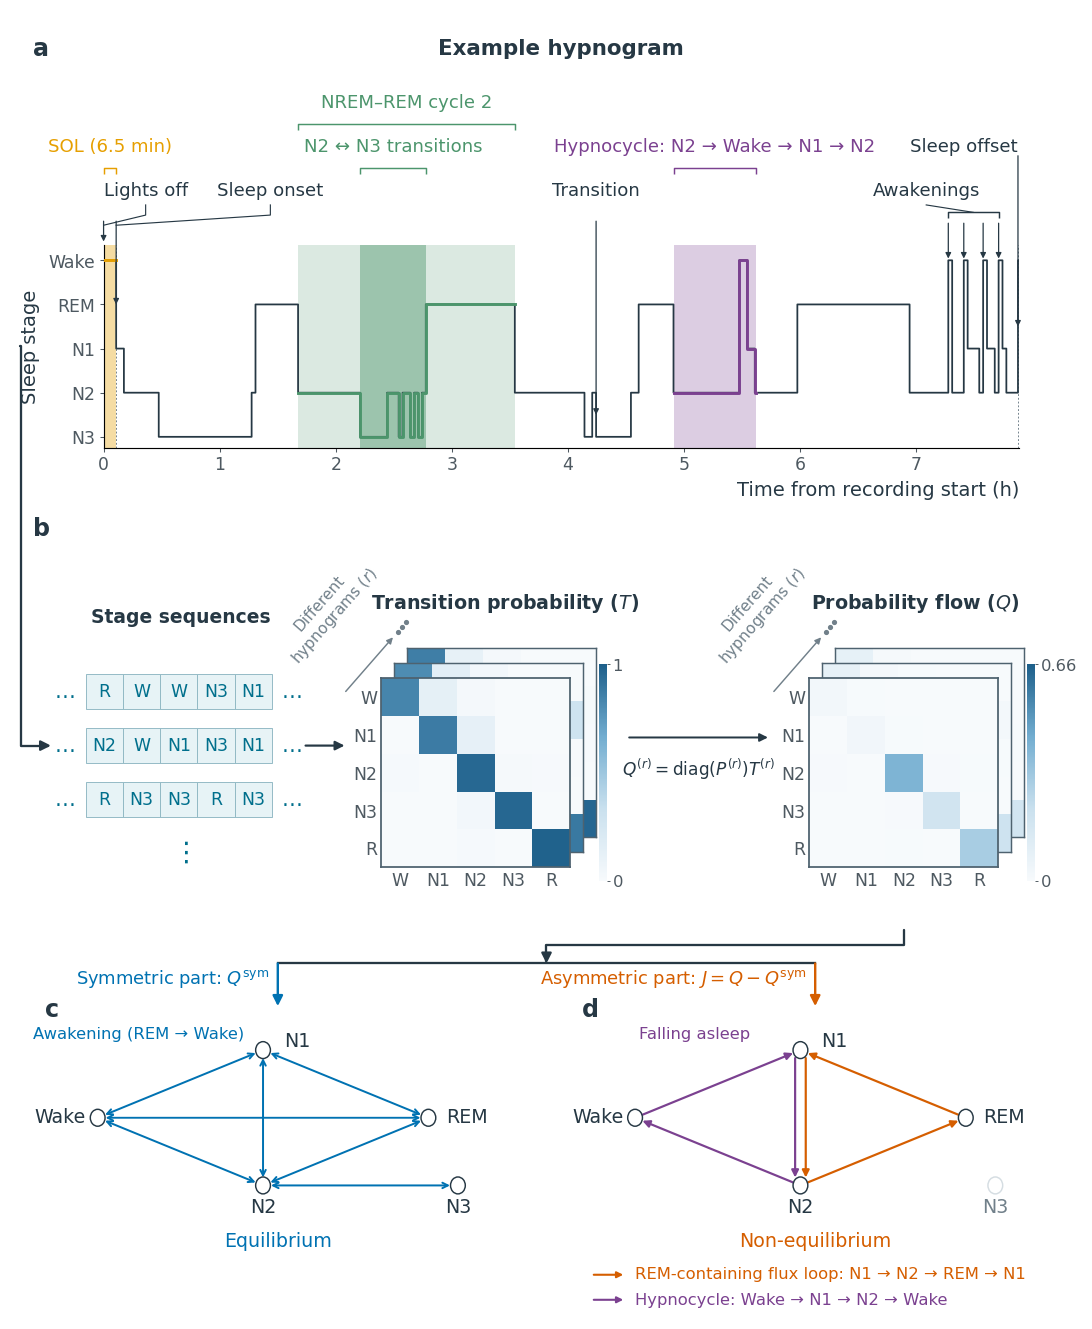

In [42]:
# Cell 2: run. Execute in the notebook where the five data variables already exist.
# Numeric hypnogram encoding is the one you confirmed: 0=WAKE,1=N1,2=N2,3=N3,4=REM.
# matrix_order specifies the actual row/column order in ALL four collections.
# ndarray shape (n,5,5): axes=(-2,-1). Shape (5,5,n): axes=(0,1).
# "auto" handles unambiguous shapes; set axes explicitly if n=5.
# Epoch intervals and sequence_start are ZERO-BASED indices, not hours.

# ---------- Change these three values to style the whole figure ----------
FONT_SIZE = 10.0         # pt: scales ALL text, preserving title/tick hierarchy.
FIG_WIDTH_MM = 180.0    # exact canvas width in mm.
FIG_HEIGHT_MM = 220.0   # exact canvas height in mm; None = automatic aspect ratio.
# -----------------------------------------------------------------------

fig1 = plot_sleep_fig1(
    font_size=FONT_SIZE,
    fig_width_mm=FIG_WIDTH_MM,
    fig_height_mm=FIG_HEIGHT_MM,
    example_hypnogram=NocHypDict[30],
    NapTmat=NapTmat,
    NocTmat=NocTmat,
    NapFS=NapFS,
    NocFS=NocFS,
    epoch_seconds=30,
    stage_map={0:"WAKE",1:"N1",2:"N2",3:"N3",4:"REM"},
    matrix_order=("WAKE","N1","N2","N3","REM"),
    t_matrix_axes="auto",
    flow_matrix_axes="auto",
    hypnocycle_index=None,    # None: actual matching motif nearest recording midpoint.
    nrem_rem_window=None,     # Optional check against the detected selected cycle.
    nrem_rem_index=1,         # ZERO-BASED: 1 selects the SECOND NREM-REM cycle.
    example_record_key=30,    # Must correspond to NocHypDict[30] in NocTmat and NocFS.
    lights_off_epoch=0,       # ASSUMPTION: recording starts at lights off. Edit if not true.
    sleep_onset_epoch=None,   # Auto: first scored sleep at/after lights off.
    sleep_offset_epoch=None,  # Auto: terminal Wake after last sleep; never guess if unobserved.
    transition_epoch=None,    # Auto-select a real stage change; or supply its epoch.
    awakening_epoch=None,     # Auto: actual late-sleep intermediate awakenings; excludes terminal Wake.
    falling_asleep_epoch=None,# First observed falling asleep, at the initial onset.
    output_dir=str(FIGURE_OUTPUT_ROOT / 'Fig1'), # Change to your preferred destination.
    basename="Fig1",
    save_formats=("pdf","svg","png"),
    dpi=600,
)
print("Individual matrix counts:", fig1["metadata"]["matrix_counts"])
print("Illustrative sequence metadata:", fig1["metadata"]["sequence"])
print("Hypnocycle source:", fig1["metadata"]["hypnocycle"])
print("Timing annotations:", fig1["metadata"]["timing"])
print("Saved files:", fig1["paths"])
plt.show()


### Main Fig. 2


Nocturnal: k=0.0 (1/51)
Nocturnal: k=1.0 (11/51)
Nocturnal: k=2.0 (21/51)
Nocturnal: k=3.0 (31/51)
Nocturnal: k=4.0 (41/51)
Nocturnal: k=5.0 (51/51)
Nap: k=0.0 (1/51)
Nap: k=1.0 (11/51)
Nap: k=2.0 (21/51)
Nap: k=3.0 (31/51)
Nap: k=4.0 (41/51)
Nap: k=5.0 (51/51)
Main figure: {'pdf': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/Fig2/Fig2_combined.pdf', 'svg': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/Fig2/Fig2_combined.svg', 'png': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/Fig2/Fig2_combined.png'}


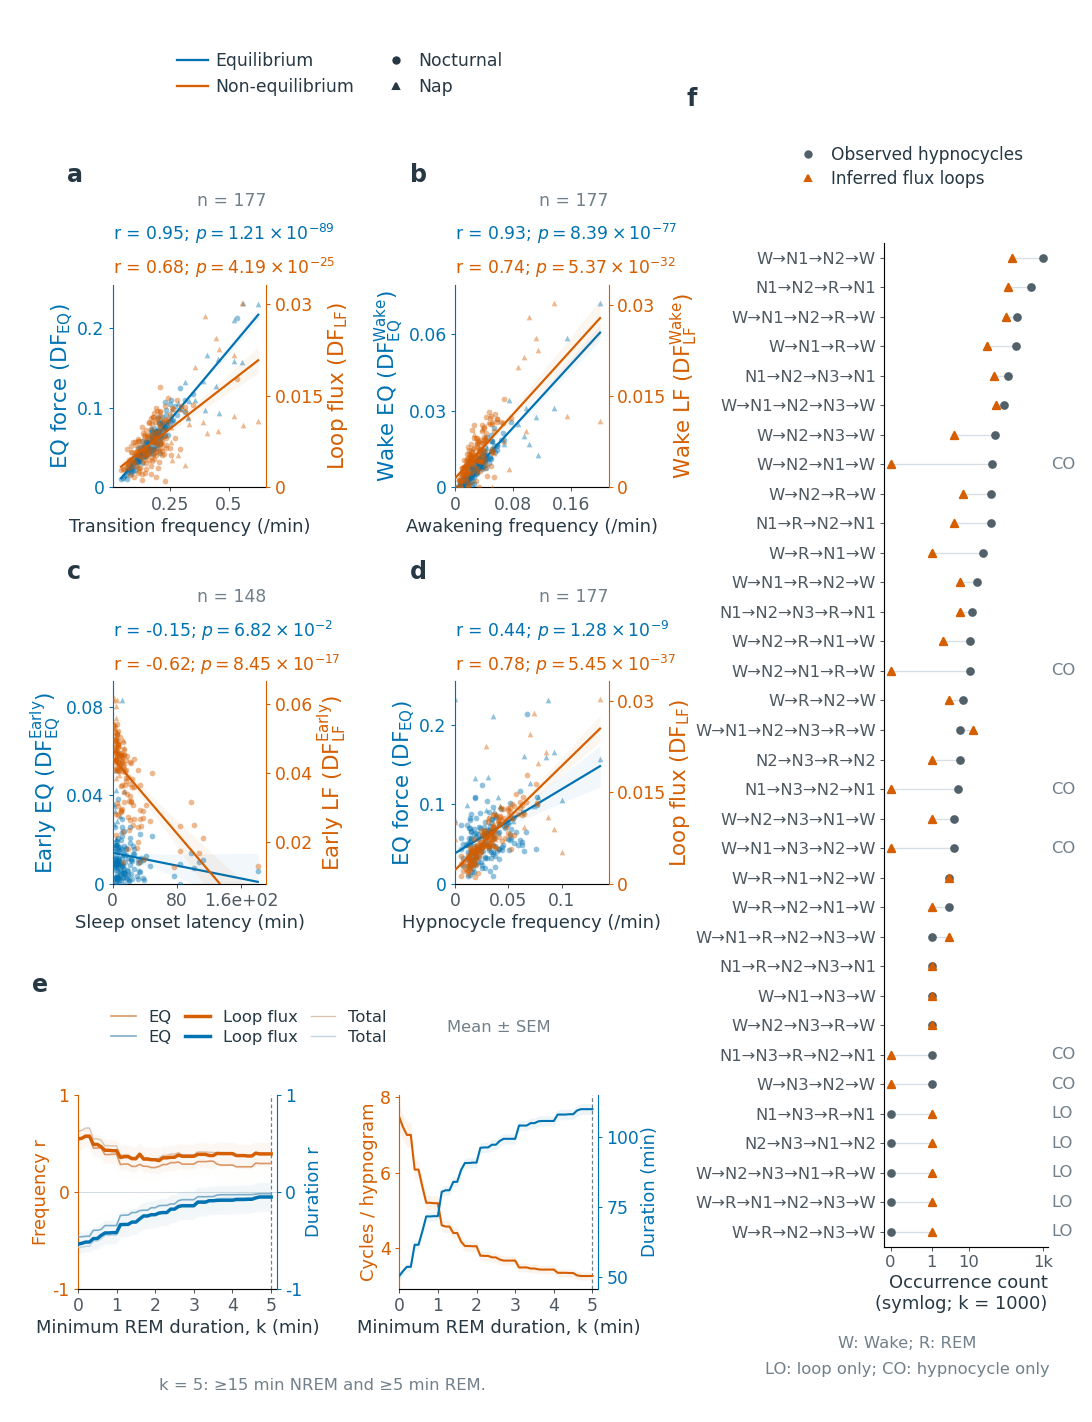

In [43]:
# Cell 2: run. Run where the data arrays/dicts listed below already exist.
# Each panel uses its own within-cohort record order; panel c may have fewer records.
# TST: minutes. Nocturnal SOL: minutes. Nap SOL: 30-second units -> minutes.

FONT_SIZE = 10.0
FIG_WIDTH_MM = 180.0
FIG_HEIGHT_MM = None   # Auto-height from all family labels; or set an exact mm height.
OUTPUT_DIR = str(FIGURE_OUTPUT_ROOT / 'Fig2')
DPI = 600
BOOTSTRAP_N = 2000            # Paired recording-level CI for Delta |r| in a-d.
RANDOM_SEED = 2026
SHOW_TREND_CI = True
RECOMPUTE_E = False           # Set True after changing raw E data or force definitions.
DURATION_WITHOUT_CYCLE = 'zero' # Original rule. 'nan' excludes undefined duration only.
K_VALUES = np.round(np.arange(51)/10,1)  # 0.0 ... 5.0 inclusive.
EPOCH_SECONDS = 30
NAP_SOL_EPOCH_SECONDS = 30

_required = [
    'NocTransNum','NapTransNum','NocTST','NapTST','NocAllSymFlux','NapAllSymFlux',
    'NocTotalFlux','NapTotalFlux','NocToWakeNum','NapToWakeNum','NocAllSymFluxToWake',
    'NapAllSymFluxToWake','NocWakeCycleStrength','NapWakeCycleStrength','NocSOL','NapSOL',
    'NocInitialFlux','NapInitialFlux','NocInitialSymFlux','NapInitialSymFlux','Noc_loop_counts','Nap_loop_counts',
    'NocHypDict','NocAllCycle','NapAllCycle','NocAllStrength','NapAllStrength',
    'NocFlux_sym_list','NapFlux_sym_list','Noc_df_occ','Nap_df_occ',
]
_missing = [name for name in _required if name not in globals()]
_nap_hypnograms = globals().get('NapHyp',globals().get('NapHypDict'))
if _nap_hypnograms is None:_missing.append('NapHyp (or NapHypDict)')
if _missing:raise NameError('Missing input data variables: '+', '.join(_missing))

association_inputs = {
    'Nocturnal':dict(TST=NocTST,TransNum=NocTransNum,ToWakeNum=NocToWakeNum,SOL=NocSOL,
        loop_counts=Noc_loop_counts,AllSymFlux=NocAllSymFlux,TotalFlux=NocTotalFlux,
        AllSymFluxToWake=NocAllSymFluxToWake,WakeCycleStrength=NocWakeCycleStrength,
        InitialFlux=NocInitialFlux,InitialSymFlux=NocInitialSymFlux),
    'Nap':dict(TST=NapTST,TransNum=NapTransNum,ToWakeNum=NapToWakeNum,SOL=NapSOL,
        loop_counts=Nap_loop_counts,AllSymFlux=NapAllSymFlux,TotalFlux=NapTotalFlux,
        AllSymFluxToWake=NapAllSymFluxToWake,WakeCycleStrength=NapWakeCycleStrength,
        InitialFlux=NapInitialFlux,InitialSymFlux=NapInitialSymFlux),
}
fig2_associations,fig2_exclusions = prepare_fig2_associations(
    association_inputs,nap_sol_epoch_seconds=NAP_SOL_EPOCH_SECONDS)

force_inputs = {
    'Nocturnal':dict(data=NocHypDict,AllCycle=NocAllCycle,AllStrength=NocAllStrength,Flux_sym_list=NocFlux_sym_list),
    'Nap':dict(data=_nap_hypnograms,AllCycle=NapAllCycle,AllStrength=NapAllStrength,Flux_sym_list=NapFlux_sym_list),
}
force_options = dict(
    include_post_rem_state=True,
    include_wake_in_structure=True,
    min_segment_edges=1,
    allow_loop_reuse=True,
    count_each_loop_once_per_cycle=True,
    sum_unique_missing_edges=True,
    multiply_loop_flux_by_n_edges=True,
)
_scan_config = (tuple(K_VALUES),EPOCH_SECONDS,DURATION_WITHOUT_CYCLE,tuple(force_options.items()))
if RECOMPUTE_E or 'fig2_scan' not in globals() or globals().get('_fig2_scan_config') != _scan_config:
    fig2_scan = scan_fig2_nremrem(force_inputs,K_VALUES,epoch_seconds=EPOCH_SECONDS,
        duration_without_cycle=DURATION_WITHOUT_CYCLE,progress=True,**force_options)
    _fig2_scan_config = _scan_config
else:
    print('Using cached fig2_scan; set RECOMPUTE_E=True if raw E data changed.')

# Counts for f are prepared before drawing the single combined figure.
fig2_family_counts = prepare_fig2_family_counts(Noc_df_occ,Nap_df_occ,NocAllCycle,NapAllCycle)
fig2 = plot_fig2_main(fig2_associations,fig2_scan,family_counts=fig2_family_counts,
    font_size=FONT_SIZE,fig_width_mm=FIG_WIDTH_MM,fig_height_mm=FIG_HEIGHT_MM,
    bootstrap_n=BOOTSTRAP_N,random_seed=RANDOM_SEED,show_trend_ci=SHOW_TREND_CI,
    output_dir=OUTPUT_DIR,dpi=DPI)

if OUTPUT_DIR is not None:
    _folder=Path(OUTPUT_DIR);_folder.mkdir(parents=True,exist_ok=True)
    for _key in ('df_corr','df_target_by_k','df_cycle_count_by_k','df_cycle_duration_by_k','df_cycle_summary_by_k'):
        fig2_scan[_key].to_csv(_folder/f'Fig2_E_{_key}.csv',index=False)
    fig2_exclusions.to_csv(_folder/'Fig2_exclusions.csv',index=False)
    (_folder/'Fig2_metadata.json').write_text(json.dumps({
        'TST_unit':'minutes','Nocturnal_SOL_unit':'minutes','Nap_SOL_input_unit_seconds':NAP_SOL_EPOCH_SECONDS,
        'E_cohorts':list(force_inputs),'E_frequency_unit':'cycles per TST minute','k_includes_5':True,
        'duration_without_cycle':DURATION_WITHOUT_CYCLE,'force_options':force_options,
        'correlation':'Pearson; pooled individual recordings',
        'displayed_correlation':'Pearson r and two-sided unadjusted p, scientific notation with superscript exponent',
        'r_CI':'95% Fisher-z retained in CSV, not displayed as bracketed ranges',
        'delta_r_CI':'Paired, cohort-stratified recording bootstrap of |r_LF|-|r_EQ|',
        'bootstrap_n':BOOTSTRAP_N,'random_seed':RANDOM_SEED,
        'plot_size_mm':(fig2['figure'].get_size_inches()*25.4).tolist(),'font_size_pt':FONT_SIZE,
        'layout':'One figure a-f: a-d 2x2 dual-y; e two dual-y plots; f full right column',
        'e_correlation_axes':'identical left/right r limits [-1,1]; orange frequency left, blue duration right; all solid',
        'flux_emphasis':'Within each target hue: loop flux 1.65 pt saturated; EQ 0.8 pt medium shade; total 0.65 pt light shade',
        'e_descriptive_axes':'orange count left, blue duration right; both solid',
        'family_count':len(fig2_family_counts),
        'grouped_correlations':'Nocturnal and Nap estimated separately for a-d and every k in e',
        'family_rule':'Exact supplied tuples, independent full occurrence counts; no intersection or new rotation',
    },ensure_ascii=False,indent=2),encoding='utf-8')

# Results available for checking or further analysis:
df_corr = fig2_scan['df_corr']
df_corr_wide = df_corr.pivot(index='k',columns=['target','component'],values='pearson_r')
df_target_by_k = fig2_scan['df_target_by_k']
df_cycle_count_by_k = fig2_scan['df_cycle_count_by_k']
df_cycle_duration_by_k = fig2_scan['df_cycle_duration_by_k']
df_cycle_summary_by_k = fig2_scan['df_cycle_summary_by_k']
print('Main figure:',fig2['paths'])
plt.show()


### Main Fig. 3


Fig3 output: {'pdf': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/Fig3/Fig3_combined.pdf', 'svg': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/Fig3/Fig3_combined.svg', 'png': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/Fig3/Fig3_combined.png'}
A: NocHypDict[30], 4 qualifying NREM-REM cycles.
 cycle_number  start_min  stop_min  nrem_before_rem_min  rem_bout_min
            1        6.5     100.5                 72.0          22.0
            2      100.5     212.5                 66.0          46.0
            3      212.5     294.5                 64.0          18.0
            4      294.5     416.5                 60.0          58.0
B duration Wilcoxon rank-sum results:
    kind  n_inside  n_outside  p_value symbol
    loop      1662        215 0.000196    ***
exchange      7333       1238 0.961568     ns
B categories: loops = 12 ; uncovered pairs = 10
C source: fig2_family_counts ;

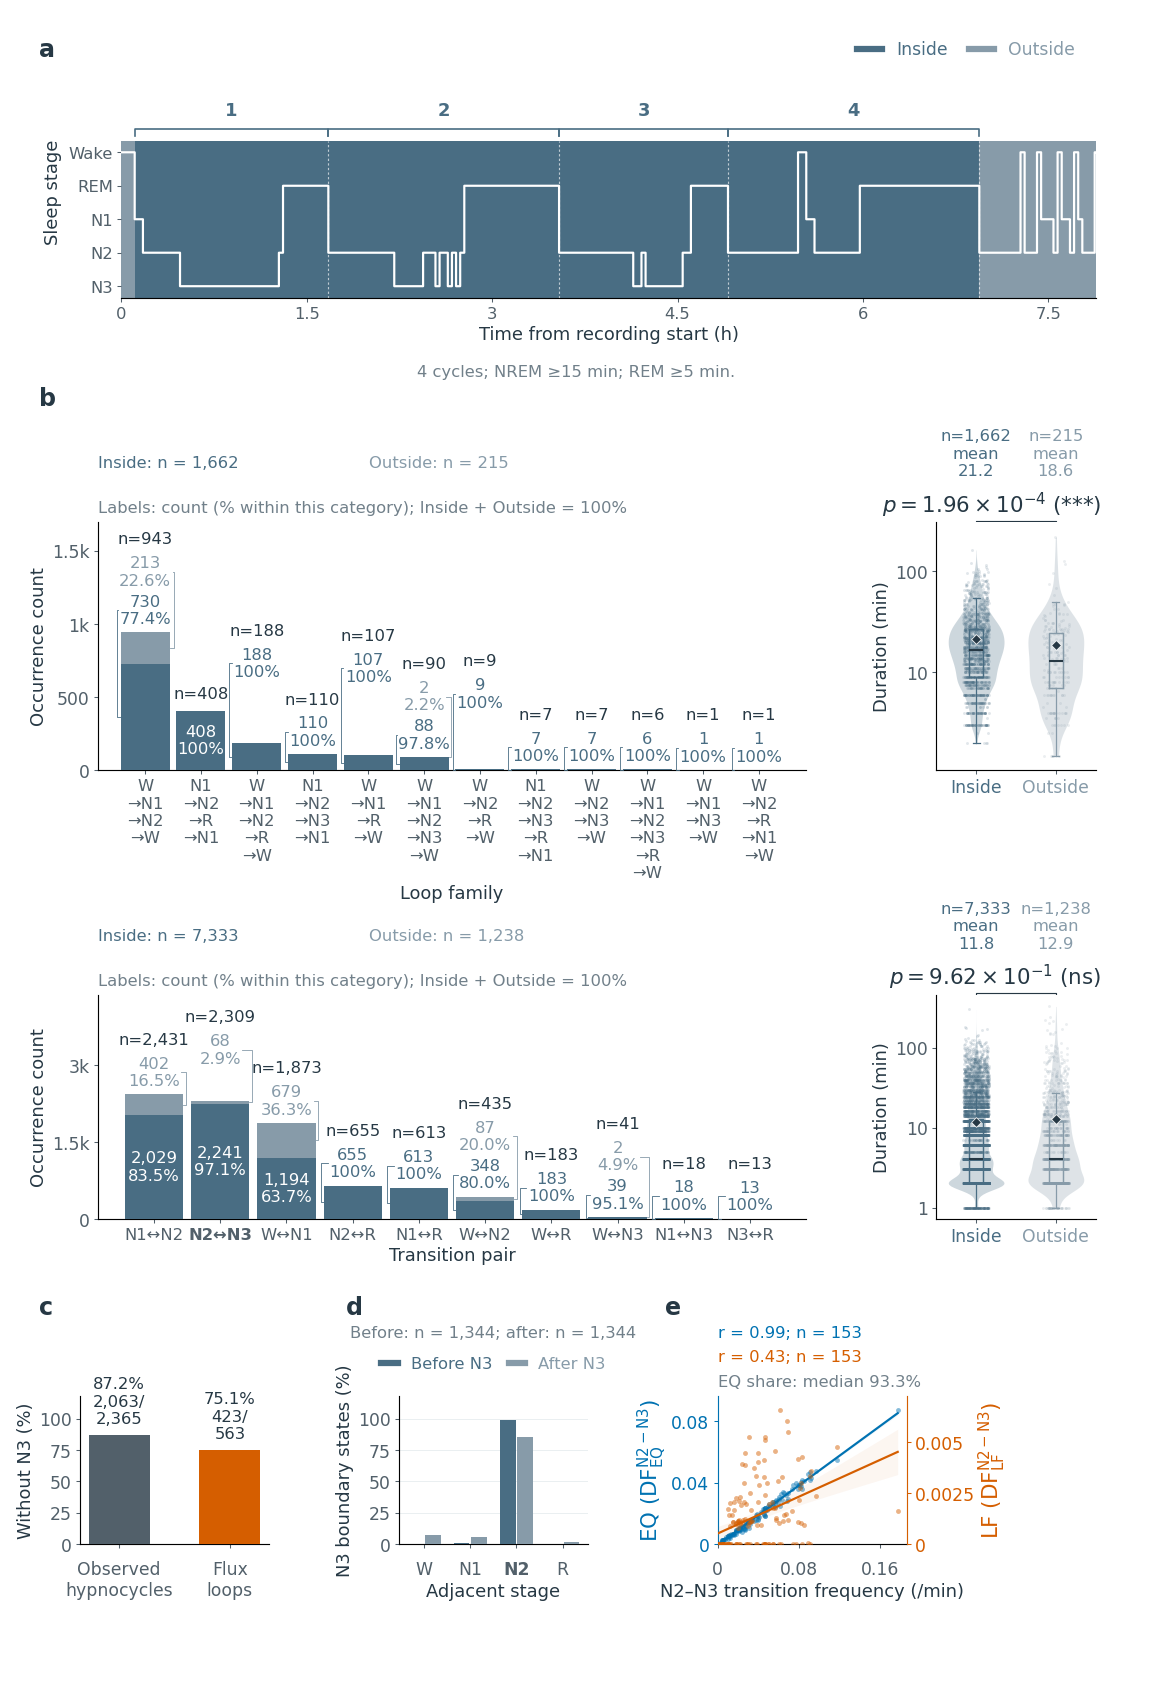

In [44]:
# Cell 2: run. Execute in the notebook containing the supplied data variables.
FONT_SIZE = 10.0
FIG_WIDTH_MM = 180.0          # Minimum overall width; auto-expands to fit both columns.
B_LEFT_WIDTH_MM = 120.0       # Physical width of BOTH left-column plots in panel b.
TRANSITION_PAIR_LABEL_SHIFT_PT = -3.0  # Negative: text left; bar/tick positions unchanged.
B_ROW_GAP_MM = 38.0          # b upper/lower plot-area gap; previously 50 mm.
B_TO_CDE_GAP_MM = 15.0        # b lower plot to c/d/e panel letters; previously 27 mm.
FIG_HEIGHT_MM = None          # Auto layout; a numeric value is the starting/minimum height.
OUTPUT_DIR = str(FIGURE_OUTPUT_ROOT / 'Fig3')
DPI = 600
EXAMPLE_HYPNOGRAM_KEY = 30   # Exact NocHypDict[30], no substitute recording.
EPOCH_SECONDS = 30.0
MIN_NREM_MINUTES = 15.0      # Same canonical thresholds as Fig1 / Fig2 at k=5.
MIN_REM_MINUTES = 5.0
SHOW_CATEGORY_PERCENTAGES = True # Segment label: count (% of this category total).
CATEGORY_LABEL_ROTATION = 0.0 # Full loop names wrap onto short lines.
CATEGORY_MODE = 'count'     # Stacked raw counts; optional 'percent' gives 100% stacks by category.
DURATION_SCALE = 'log'        # 'linear' also retains every valid event; no percentile truncation.
EXCHANGE_DURATION_FACTOR = 2.0 # Original code: 2 * exchange_unit_duration_min, an estimate.
N2N3_FREQUENCY_FACTOR = 2.0   # Original call: Noc_N2N3_freq * 2; input and output are /min.
SHOW_ALL_DURATION_POINTS = True
SHOW_DURATION_TEST = True     # Two-sided Wilcoxon rank-sum, pooled events, unadjusted p.
SHOW_REGRESSION_CI = True
SHOW_EQ_SHARE = True          # Descriptive median EQ/(EQ+LF), not a new significance test.
MIN_N_PER_GROUP = 3
RANDOM_SEED = 2026

# B must use the FULL occurrence-weighted family table, including loop-only/cycle-only rows.
# Prefer the variable supplied in your original call; latest Fig2 is a compatible alternative.
# Fig2's complete family table is the explicit source; no stale plot_df fallback.
FIG3_FAMILY_COUNTS = fig2_family_counts
_fig3_family_source_name = 'fig2_family_counts'

_required = ['df_loop_occurrence','df_reversible_occurrence','NocHypDict',
             'Noc_N2N3_freq','NocAllLoopFlux_N2N3','NocAllSymFlux_N2N3']
_missing = [name for name in _required if name not in globals()]
if _missing:raise NameError('Missing Fig3 input variables: '+', '.join(_missing))

fig3_data = prepare_fig3_data(
    df_loop_occurrence=df_loop_occurrence,
    df_reversible_occurrence=df_reversible_occurrence,
    family_counts=FIG3_FAMILY_COUNTS,
    NocHypDict=NocHypDict,
    Noc_N2N3_freq=Noc_N2N3_freq,
    NocAllLoopFlux_N2N3=NocAllLoopFlux_N2N3,
    NocAllSymFlux_N2N3=NocAllSymFlux_N2N3,
    exchange_duration_factor=EXCHANGE_DURATION_FACTOR,
    frequency_factor=N2N3_FREQUENCY_FACTOR,
    min_n_per_group=MIN_N_PER_GROUP,example_hypnogram_key=EXAMPLE_HYPNOGRAM_KEY,
    epoch_seconds=EPOCH_SECONDS,min_nrem_minutes=MIN_NREM_MINUTES,min_rem_minutes=MIN_REM_MINUTES,
)
fig3_data['metadata']['C_source_variable'] = _fig3_family_source_name
fig3_data['metadata']['B_cohort'] = 'As supplied in occurrence tables; no nocturnal/nap filter applied.'
fig3_data['metadata']['C_cohort'] = 'As supplied in full family-count table; no nocturnal/nap filter applied.'

fig3 = plot_fig3(
    fig3_data,font_size=FONT_SIZE,fig_width_mm=FIG_WIDTH_MM,fig_height_mm=FIG_HEIGHT_MM,b_left_width_mm=B_LEFT_WIDTH_MM,
    transition_pair_label_shift_pt=TRANSITION_PAIR_LABEL_SHIFT_PT,
    b_row_gap_mm=B_ROW_GAP_MM,b_to_cde_gap_mm=B_TO_CDE_GAP_MM,
    category_mode=CATEGORY_MODE,duration_scale=DURATION_SCALE,
    show_category_percentages=SHOW_CATEGORY_PERCENTAGES,category_label_rotation=CATEGORY_LABEL_ROTATION,
    show_points=SHOW_ALL_DURATION_POINTS,show_duration_test=SHOW_DURATION_TEST,show_regression_ci=SHOW_REGRESSION_CI,
    show_eq_share=SHOW_EQ_SHARE,random_seed=RANDOM_SEED,output_dir=OUTPUT_DIR,dpi=DPI,
)
Fig3ACycles = fig3['a_cycle_table']
Fig3AHypnogramSource = fig3['a_hypnogram_source']
fig3_summary_without_N3 = fig3_data['without_n3']
fig3_duration_statistics = fig3_data['duration_stats']
fig3_duration_wilcoxon = fig3_data['duration_rank_tests']
fig3_N3_boundary_statistics = fig3_data['n3_boundaries']
fig3_D_correlations = fig3_data['d_stats']

print('Fig3 output:',fig3['paths'])
print(f'A: NocHypDict[{EXAMPLE_HYPNOGRAM_KEY!r}], {len(Fig3ACycles)} qualifying NREM-REM cycles.')
print(Fig3ACycles[['cycle_number','start_min','stop_min','nrem_before_rem_min','rem_bout_min']].to_string(index=False))
print('B duration Wilcoxon rank-sum results:')
print(fig3_duration_wilcoxon[['kind','n_inside','n_outside','p_value','symbol']].to_string(index=False))
print('B categories: loops =',len(fig3_data['loop_categories']),
      '; uncovered pairs =',len(fig3_data['exchange_categories']))
print('C source:',_fig3_family_source_name,'; must contain every family, not a top-N subset.')
print('D: Nocturnal N3 episodes; E: Nocturnal recording-level vectors, frequency x2 retained.')
plt.show()


### Main Fig. 4


/home/datadisk1/wxy/jupyter_notebook/tmp/ipykernel_1531680/1383769197.py:24: UserWarning: Fig4 exported with layout review notes; see text_geometry.json: Flux
removed / Awakening
frequency (/min)
  fig4 = plot_fig4(fig4_data,font_size=FONT_SIZE,fig_width_mm=FIG_WIDTH_MM,fig_height_mm=FIG_HEIGHT_MM,
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


Fig4 output: {'pdf': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/Fig4/Fig4_combined.pdf', 'svg': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/Fig4/Fig4_combined.svg', 'png': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/Fig4/Fig4_combined.png'}
    metric  n_pairs  change_ratio_of_means_percent      p_value
       SOL      174                      97.099244 6.843623e-30
Hypnocycle      177                     -39.672141 4.246994e-31
 Awakening      177                     -36.302582 7.025109e-29
Transition      177                     -29.693357 4.246994e-31
A: schematic. B: pooled Nap + Nocturnal. C: Nocturnal only. Both SOL inputs are minutes.
C retains all four original tests; magnitude comparisons use absolute percent change.


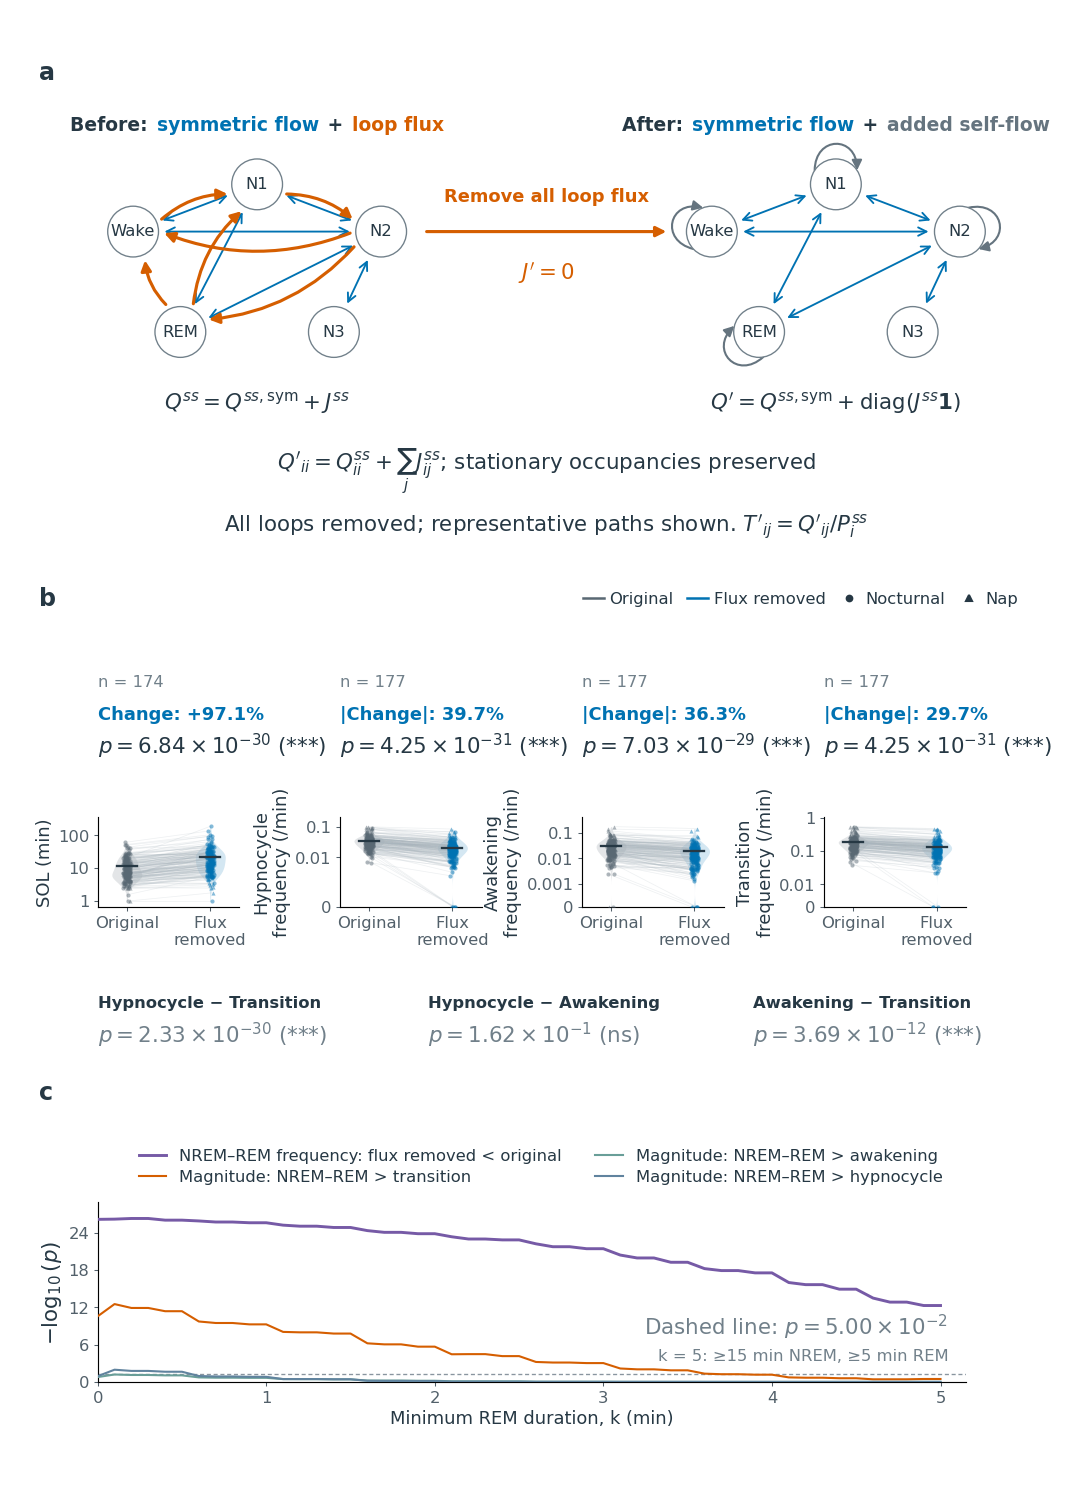

In [45]:
# Cell 2: run in the notebook containing the supplied simulation summaries.
FONT_SIZE = 10.0
FIG_WIDTH_MM = 180.0
FIG_HEIGHT_MM = 250.0      # Physical canvas height; all font sizes stay fixed.
OUTPUT_DIR = str(FIGURE_OUTPUT_ROOT / 'Fig4')
DPI = 600
K_STATIC = None            # Original rule: earliest available k per recording.
BOOTSTRAP_N = 0           # No confidence intervals requested; no bootstrap needed.
RANDOM_SEED = 2026
TOP_SCALE = 'auto'         # Positive data: log; zeros present: symlog. No epsilon added.
SHOW_CI = False            # Show p values and change percentages, without confidence intervals.
STRICT_LAYOUT = False     # Export normally; any remaining layout findings are saved as diagnostics.
PLOT_P_FLOOR = 1e-300      # Display only; censored points are marked, raw p is preserved.

# Confirmed units: both simulated SOL columns and both TST vectors are minutes.
_required = ['Nap_df_subject_k','Noc_df_subject_k','NapTST','NocTST']
_missing = [name for name in _required if name not in globals()]
if _missing:raise NameError('Missing Fig4 inputs: '+', '.join(_missing))

fig4_data = prepare_fig4(
    Nap_df_subject_k=Nap_df_subject_k,Noc_df_subject_k=Noc_df_subject_k,
    NapTST=NapTST,NocTST=NocTST,k_static=K_STATIC,n_boot=BOOTSTRAP_N,random_seed=RANDOM_SEED,
)
fig4 = plot_fig4(fig4_data,font_size=FONT_SIZE,fig_width_mm=FIG_WIDTH_MM,fig_height_mm=FIG_HEIGHT_MM,
    top_scale=TOP_SCALE,show_ci=SHOW_CI,p_plot_floor=PLOT_P_FLOOR,random_seed=RANDOM_SEED,output_dir=OUTPUT_DIR,dpi=DPI,strict_layout=STRICT_LAYOUT)

fig4_figure = fig4['figure']
fig4_axes = fig4['axes']
fig4_B_statistics = fig4_data['a_stats']
fig4_B_reduction_comparisons = fig4_data['a_contrasts']
fig4_p_by_k = fig4_data['p_by_k']
fig4_C_tests = fig4_data['b_tests']

print('Fig4 output:',fig4['paths'])
print(fig4_B_statistics[['metric','n_pairs','change_ratio_of_means_percent','p_value']].to_string(index=False))
print('A: schematic. B: pooled Nap + Nocturnal. C: Nocturnal only. Both SOL inputs are minutes.')
print('C retains all four original tests; magnitude comparisons use absolute percent change.')
_variation = fig4_data['static_variation']
if _variation.varies_across_k.any():
    print('Static columns vary across k for',_variation.loc[_variation.varies_across_k,'hypnogram_id'].nunique(),
          'recordings; original first-nonmissing selection retained. Check static_variation.csv.')
if not fig4_data['metadata']['canonical_k5_present']:
    print('k=5 is not in the supplied data; the reference line is shown, but no k=5 result is invented or interpolated.')
plt.show()

## 7. Final supplementary figures


### Supplementary Fig. 1


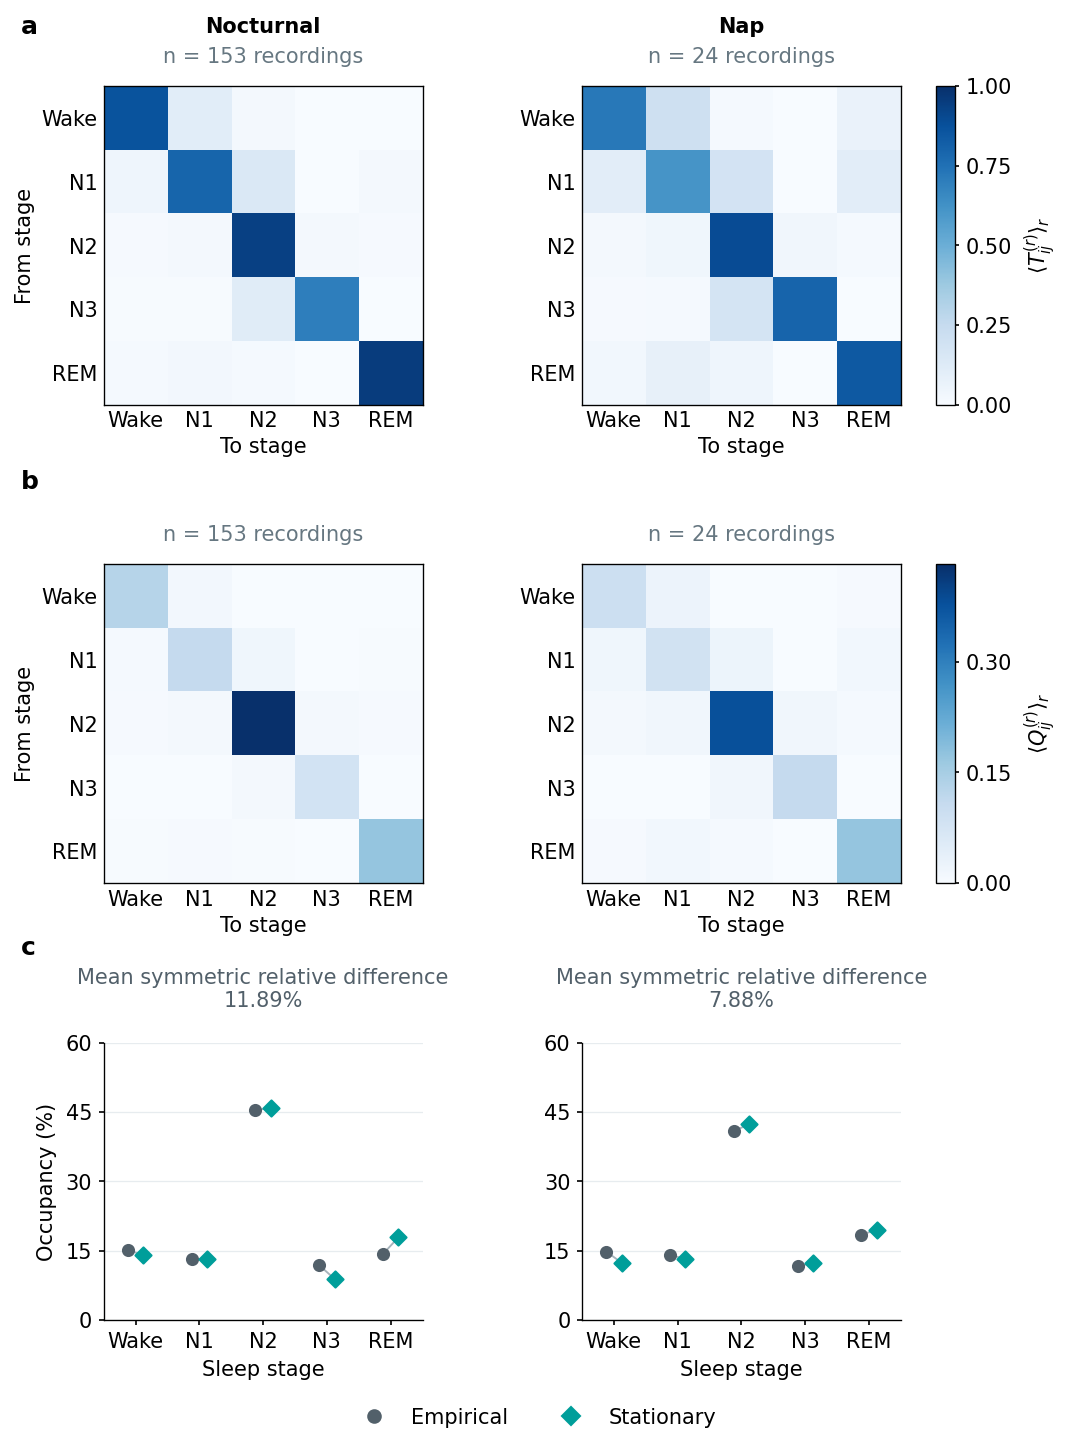

SI Fig1 output: {'pdf': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig1/SI_Fig1.pdf', 'svg': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig1/SI_Fig1.svg', 'png': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig1/SI_Fig1.png', 'matrix_means': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig1/SI_Fig1_matrix_means.csv', 'occupancy_means': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig1/SI_Fig1_occupancy_means.csv', 'relative_difference': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig1/SI_Fig1_relative_difference.csv'}
Nocturnal : T matrices = 153 , Q matrices = 153 ; mean symmetric relative difference = 11.89%
Nap : T matrices = 24 , Q matrices = 24 ; mean symmetric relative difference = 7.88%


In [46]:
# Cell 2: run in the notebook containing your original data.
FONT_SIZE = 10.0
PANEL_LABEL_SIZE = 12.0
FIG_WIDTH_MM = 180.0
FIG_HEIGHT_MM = 252.0
OUTPUT_DIR = str(FIGURE_OUTPUT_ROOT / 'SI_Fig1')
DPI = 600
SHOW_MATRIX_VALUES = False
SHOW_RELATIVE_DIFFERENCE = True
T_MATRIX_AXES = 'auto'   # For ambiguous (5,5,5), set (-2,-1) or (0,1).
Q_MATRIX_AXES = 'auto'

_needed = ['NocTmat','NapTmat','NocFS','NapFS','NocPss','NocProbs','NapPss','NapProbs']
_missing = [name for name in _needed if name not in globals()]
if _missing:
    raise NameError('Missing SI Fig1 inputs: '+', '.join(_missing))

si_fig1 = plot_si_fig1(
    NocTmat=NocTmat, NapTmat=NapTmat, NocFS=NocFS, NapFS=NapFS,
    NocPss=NocPss, NocProbs=NocProbs, NapPss=NapPss, NapProbs=NapProbs,
    font_size=FONT_SIZE,panel_label_size=PANEL_LABEL_SIZE,
    fig_width_mm=FIG_WIDTH_MM,fig_height_mm=FIG_HEIGHT_MM,
    t_matrix_axes=T_MATRIX_AXES,q_matrix_axes=Q_MATRIX_AXES,
    show_matrix_values=SHOW_MATRIX_VALUES,show_relative_difference=SHOW_RELATIVE_DIFFERENCE,
    output_dir=OUTPUT_DIR,dpi=DPI,show=True,
)
print('SI Fig1 output:',si_fig1['paths'])
for cohort,result in si_fig1['summaries'].items():
    print(cohort,': T matrices =',result['n_T'],', Q matrices =',result['n_Q'],
          '; mean symmetric relative difference =',f"{result['relative_difference']:.2%}")


### Supplementary Fig. 2


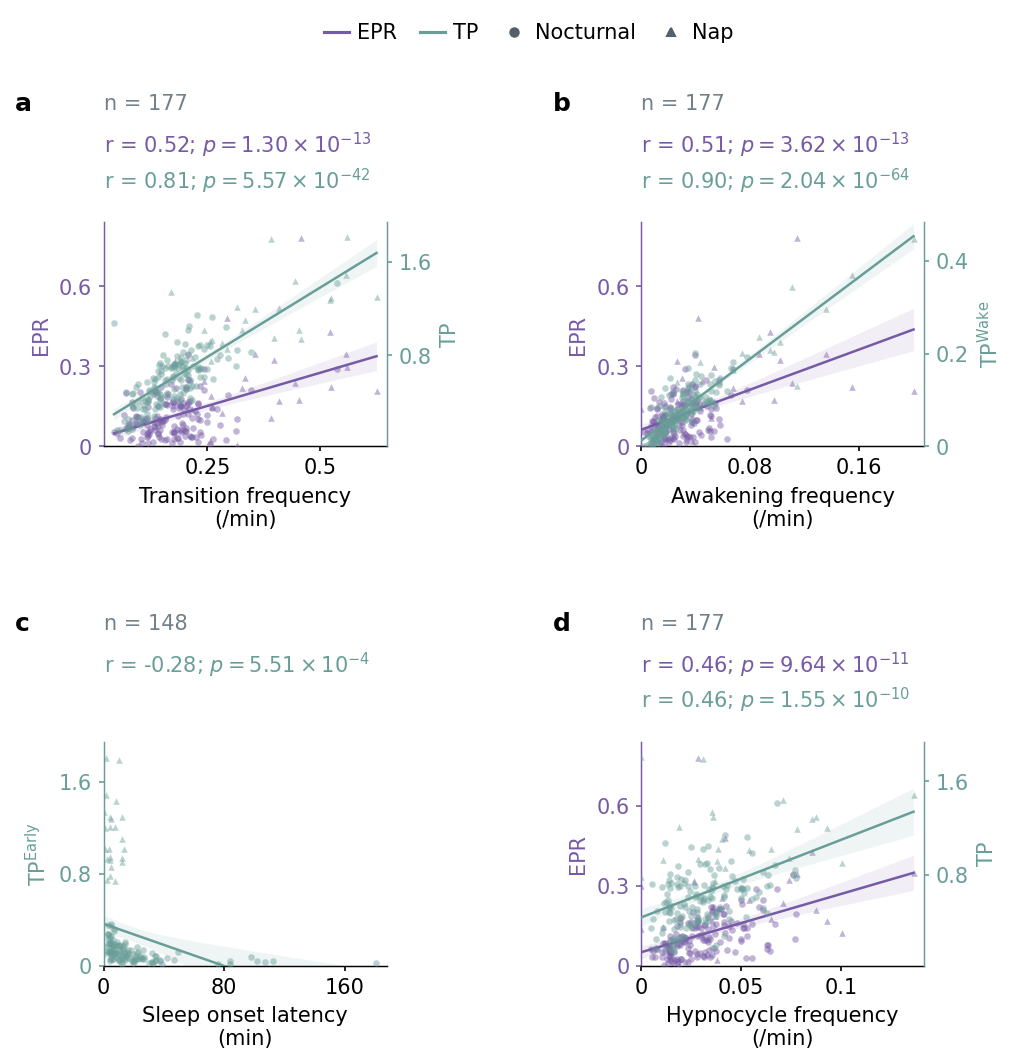

SI Fig2 output: {'pdf': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig2/SI_Fig2.pdf', 'svg': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig2/SI_Fig2.svg', 'png': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig2/SI_Fig2.png', 'statistics': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig2/SI_Fig2_statistics.csv', 'source': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig2/SI_Fig2_source.csv', 'sample_counts': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig2/SI_Fig2_sample_counts.csv'}
a EPR n = 177 ; r = 0.5193 ; p = 1.2977e-13
a TP n = 177 ; r = 0.8075 ; p = 5.5716e-42
b EPR n = 177 ; r = 0.5111 ; p = 3.6223e-13
b TP n = 177 ; r = 0.8983 ; p = 2.0387e-64
c TP n = 148 ; r = -0.2806 ; p = 0.00055066
d EPR n = 177 ; r = 0.4620 ; p = 9.6412e-11
d TP n = 177 ; r = 0.

In [47]:
# Cell 2: run in your data notebook. No plot_dual_xy_regression def required.
FONT_SIZE = 10.0
PANEL_LABEL_SIZE = 12.0
FIG_WIDTH_MM = 180.0
FIG_HEIGHT_MM = 184.0
OUTPUT_DIR = str(FIGURE_OUTPUT_ROOT / 'SI_Fig2')
DPI = 600
SHOW_REGRESSION_CI = True  # 95% CI for fitted mean, not for Pearson r.
NAP_SOL_EPOCH_SECONDS = 30.0
EPR_AXIS_LABEL = 'EPR'    # Original EPR units retained; add your unit here if needed.

_required = ['NocAllNoDiagT','NapAllNoDiagT','NocAllNoDiagTWake','NapAllNoDiagTWake',
    'NocEPRss','NapEPRss','NocTransNum','NapTransNum','NocTST','NapTST',
    'NocToWakeNum','NapToWakeNum','Noc_loop_counts','Nap_loop_counts',
    'NocSOL','NapSOL','NocAllNoDiagT_ForSOL']
_missing = [name for name in _required if name not in globals()]
if _missing:raise NameError('Missing SI Fig2 input variables: '+', '.join(_missing))

si_fig2_inputs = {
    'Nocturnal':dict(TST=NocTST,TransNum=NocTransNum,ToWakeNum=NocToWakeNum,
        loop_counts=Noc_loop_counts,EPR=NocEPRss,TP=NocAllNoDiagT,TPWake=NocAllNoDiagTWake,
        SOL=NocSOL,TPSOL=NocAllNoDiagT_ForSOL),
    'Nap':dict(TST=NapTST,TransNum=NapTransNum,ToWakeNum=NapToWakeNum,
        loop_counts=Nap_loop_counts,EPR=NapEPRss,TP=NapAllNoDiagT,TPWake=NapAllNoDiagTWake,
        SOL=NapSOL,TPSOL=NapAllNoDiagT),
}
si_fig2_data = prepare_si_fig2(si_fig2_inputs,nap_sol_epoch_seconds=NAP_SOL_EPOCH_SECONDS)
si_fig2 = plot_si_fig2(si_fig2_data,font_size=FONT_SIZE,panel_label_size=PANEL_LABEL_SIZE,
    fig_width_mm=FIG_WIDTH_MM,fig_height_mm=FIG_HEIGHT_MM,
    show_regression_ci=SHOW_REGRESSION_CI,epr_axis_label=EPR_AXIS_LABEL,
    output_dir=OUTPUT_DIR,dpi=DPI,show=True)

print('SI Fig2 output:',si_fig2['paths'])
for result in si_fig2['statistics']:
    print(result['panel'],result['component'],'n =',result['n'],
          '; r =',f"{result['pearson_r']:.4f}",'; p =',f"{result['pearson_p']:.5g}")


### Supplementary Fig. 3


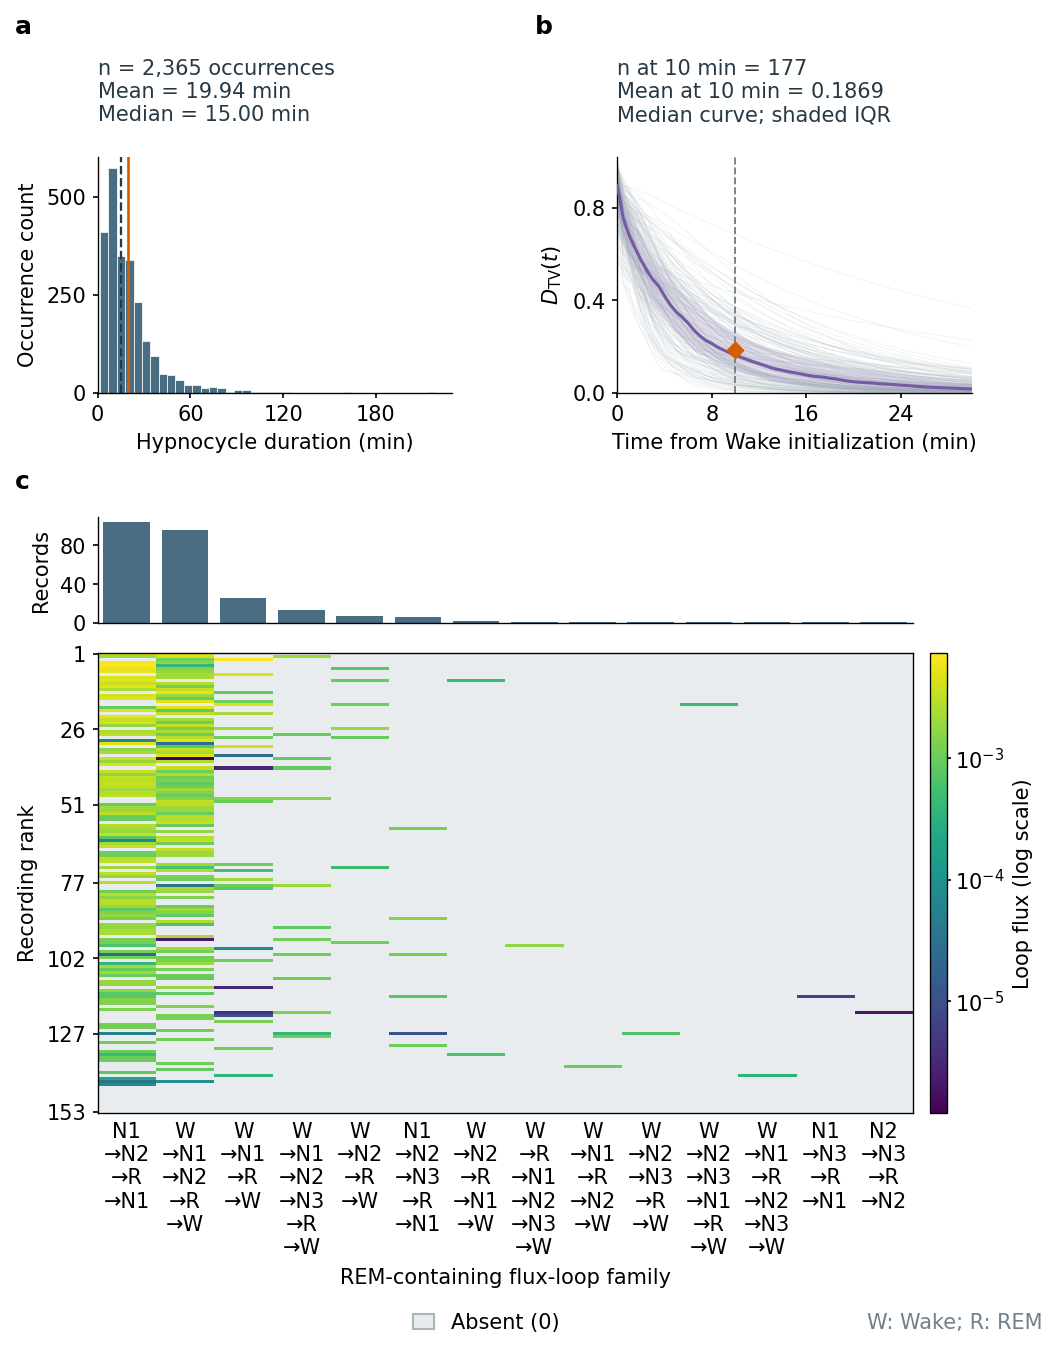

SI Fig3 output: {'pdf': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig3/SI_Fig3.pdf', 'svg': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig3/SI_Fig3.svg', 'png': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig3/SI_Fig3.png', 'duration_source': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig3/SI_Fig3_duration_source.csv', 'curve_summary': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig3/SI_Fig3_curve_summary.csv', 'curve_source': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig3/SI_Fig3_curve_source.csv', 'trajectory_audit': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig3/SI_Fig3_trajectory_audit.csv', 'loop_summary': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig3/SI_Fig3_loop_summary

In [48]:
# Cell 2: run. No original histogram / distance / heatmap defs required.
FONT_SIZE = 10.0
PANEL_LABEL_SIZE = 12.0
FIG_WIDTH_MM = 180.0
FIG_HEIGHT_MM = 236.0
OUTPUT_DIR = str(FIGURE_OUTPUT_ROOT / 'SI_Fig3')
DPI = 600
DURATION_BINS = 40
EPOCH_SECONDS = 30.0
TARGET_MIN = 10.0
CURVE_MAX_MIN = 30.0   # Early transient window; None displays the full supplied time range.
MATRIX_TYPE = 'orig'
ORDER_BY = 'occurrence'  # 'mean_flux' or 'given' (original column order) also supported.
SORT_RECORDS = True      # Descending total selected-loop flux; row-ID mapping exported.
SHOW_INDIVIDUAL_CURVES = True

_required=['Noc_df_occ','Nap_df_occ','Noc_df_steady','Nap_df_steady','Noc_loop_matrix']
_missing=[k for k in _required if k not in globals()]
if _missing:raise NameError('Missing SI Fig3 inputs: '+', '.join(_missing))

si_fig3_data=prepare_si_fig3(Noc_df_occ,Nap_df_occ,Noc_df_steady,Nap_df_steady,Noc_loop_matrix,
    duration_col='duration_min',matrix_type=MATRIX_TYPE,epoch_seconds=EPOCH_SECONDS,
    target_min=TARGET_MIN,curve_max_min=CURVE_MAX_MIN,order_by=ORDER_BY,sort_records=SORT_RECORDS)
si_fig3=plot_si_fig3(si_fig3_data,font_size=FONT_SIZE,panel_label_size=PANEL_LABEL_SIZE,
    fig_width_mm=FIG_WIDTH_MM,fig_height_mm=FIG_HEIGHT_MM,duration_bins=DURATION_BINS,
    show_individual_curves=SHOW_INDIVIDUAL_CURVES,output_dir=OUTPUT_DIR,dpi=DPI,show=True)
print('SI Fig3 output:',si_fig3['paths'])
print('a duration summary:',si_fig3_data['duration_summary'])
print('b TV at',TARGET_MIN,'min: n =',len(si_fig3_data['target_values']),
      '; mean =',float(si_fig3_data['target_values'].mean()))
print('c: all',si_fig3_data['loop_matrix'].shape[1],'REM-containing flux-loop families across',
      si_fig3_data['loop_matrix'].shape[0],'nocturnal records.')


### Supplementary Fig. 4


/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/Code/Sleep_NC_definitions.py:7869: UserWarning: Some supplied matrix pairs fail the reconstruction checks; see validation CSV. Values have not been altered.
  warnings.warn('Some supplied matrix pairs fail the reconstruction checks; see validation CSV. Values have not been altered.')
'created' timestamp seems very low; regarding as unix timestamp
'modified' timestamp seems very low; regarding as unix timestamp


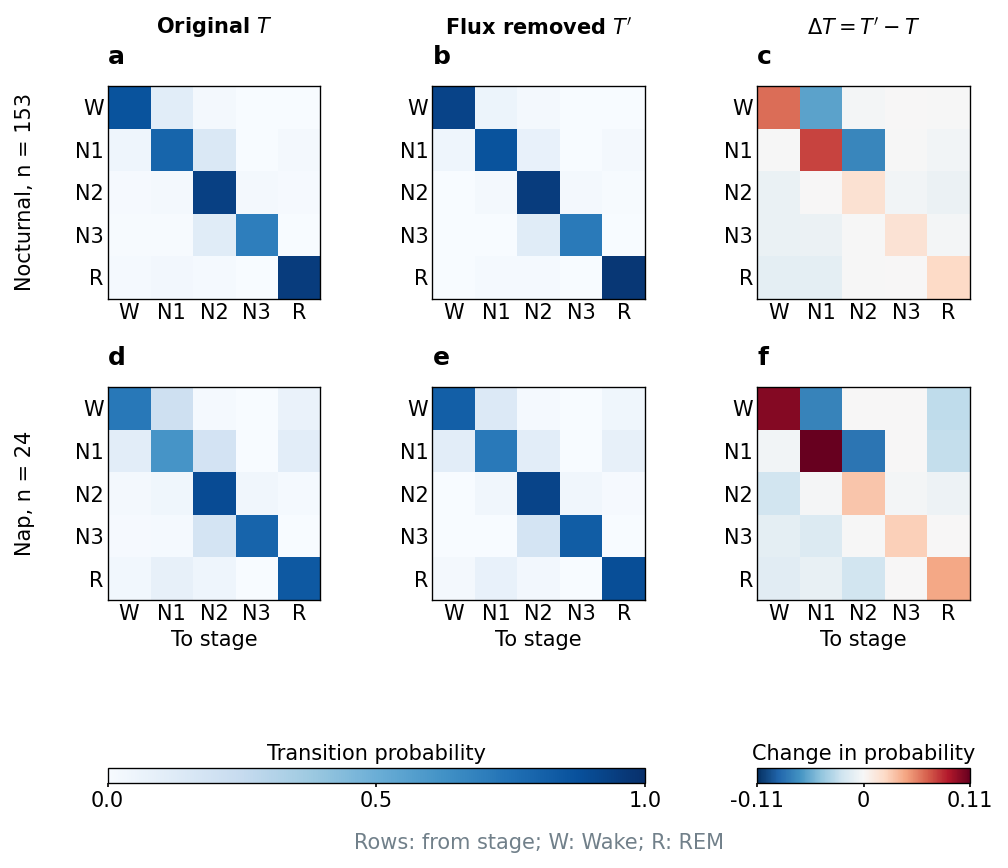

SI Fig4 output: {'pdf': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig4/SI_Fig4.pdf', 'svg': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig4/SI_Fig4.svg', 'png': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig4/SI_Fig4.png', 'paired_source': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig4/SI_Fig4_paired_source.csv', 'mean_cells': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig4/SI_Fig4_mean_cells.csv', 'validation': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Fig4/SI_Fig4_validation.csv'}
Nocturnal: positional pairing in original supplied order; equal lengths checked; supplied per-record stationary vectors; matrix order retained
Nap: positional pairing in original supplied order; equal lengths checked; supplied per-record stationary vectors; matrix order reta

In [49]:
# Cell 2: run. Use original per-record collections, not already averaged matrices.
FONT_SIZE = 10.0
PANEL_LABEL_SIZE = 12.0
FIG_WIDTH_MM = 180.0
FIG_HEIGHT_MM = 148.0
OUTPUT_DIR = str(FIGURE_OUTPUT_ROOT / 'SI_Fig4')
DPI = 600
ORIGINAL_MATRIX_AXES = 'auto'
REMOVED_MATRIX_AXES = 'auto'
NOC_REMOVED_IDS = None   # Optional IDs in Noc_T_eq_list order, if different from original dict order.
NAP_REMOVED_IDS = None
VALIDATION_TOLERANCE = 1e-8

_required=['NocTmat','NapTmat','Noc_T_eq_list','Nap_T_eq_list']
_missing=[k for k in _required if k not in globals()]
if _missing:raise NameError('Missing SI Fig4 inputs: '+', '.join(_missing))

si_fig4_data=prepare_si_fig4(NocTmat,NapTmat,Noc_T_eq_list,Nap_T_eq_list,
    NocPss=globals().get('NocPss'),NapPss=globals().get('NapPss'),
    original_matrix_axes=ORIGINAL_MATRIX_AXES,removed_matrix_axes=REMOVED_MATRIX_AXES,
    noc_removed_ids=NOC_REMOVED_IDS,nap_removed_ids=NAP_REMOVED_IDS,
    validation_tolerance=VALIDATION_TOLERANCE)
si_fig4=plot_si_fig4(si_fig4_data,font_size=FONT_SIZE,panel_label_size=PANEL_LABEL_SIZE,
    fig_width_mm=FIG_WIDTH_MM,fig_height_mm=FIG_HEIGHT_MM,output_dir=OUTPUT_DIR,dpi=DPI,show=True)
print('SI Fig4 output:',si_fig4['paths'])
for note in si_fig4_data['metadata']['messages']:print(note)
print('Per-record validation:',si_fig4_data['audit'].groupby(['cohort','validation_status']).size().to_dict())


## Notes on scope and reproducibility

* 本次整理保留原计算定义，只有 SI 3b 的距离度量按确认改为 TV；不要沿用旧的 max_abs 数值。
* SI 3c 保留原矩阵；后续 caption 也应将 selected flux loops 改为 REM-containing flux loops。
* `NocAllLoopFluxToN3` / `NapAllLoopFluxToN3` 在原代码中取的是列 4（REM）；这些变量未被最终图使用，保留原样以免静默改变含义，不应按 N3 指标解释。
* 本机未获得原 `Code` 模块及数据目录，未完整重跑真实数据；语法、notebook JSON 结构、函数来源、关键局部数值等价及依赖顺序检查见附带报告。
* 旧分支的完整源码在归档 notebook 中可查，原始文件及其历史输出仍在桌面。

函数定义位于 `Code/Sleep_NC_definitions.py`；不要只上传 notebook。


## 8. Drug dataset — Sleep-EDF Telemetry

本节读取 `PROJECT_ROOT/SleepEDF_Telemetry/` 中的 hypnogram EDF 和 `ST-subjects.xls`。
先按 subject/night 匹配，再检查 Placebo / Temazepam 顺序；保留原有标签处理、TST 分钟单位和完整 hypnogram 的 transition/loop 计算范围。
数据计算在主图 5 和 SI 图 5 的绘图调用之前完成；所有 def 已在同一个 `.py` 文件中。


In [4]:
# ============================================================
# CELL 2 — RUN
# 加载数据并分别生成 Placebo 和 Temazepam 变量
# ============================================================

from IPython.display import display


# ============================================================
# 1. 路径
# ============================================================

folder = Path(
    "SleepEDF_Telemetry"
)

xls_path = (
    folder
    / "ST-subjects.xls"
)

if not folder.exists():
    raise FileNotFoundError(
        f"找不到数据文件夹：{folder.resolve()}"
    )

if not xls_path.exists():
    raise FileNotFoundError(
        f"找不到 Excel 文件：{xls_path.resolve()}"
    )


# ============================================================
# 2. 加载全部 Hypnogram
# 顺序：subject 升序，同一 subject 内 night 升序
# ============================================================

all_epochs = load_telemetry_hypnograms(
    root_dir=folder,
    pattern="*-Hypnogram.edf",
)

print(
    f"成功读取 {len(all_epochs)} 个 Hypnogram EDF。"
)


# ============================================================
# 3. 读取 ST-subjects.xls
# ============================================================

subject_df, st_night_df = (
    read_telemetry_subjects(
        xls_path
    )
)

print(
    f"Excel 中有 {len(subject_df)} 名受试者，"
    f"{len(st_night_df)} 晚记录。"
)


# ============================================================
# 4. 根据 subject/night 显式匹配，并计算 lights off index
# ============================================================

rows_df, matched_df = (
    match_telemetry_records(
        all_epochs=all_epochs,
        night_df=st_night_df,
    )
)


# ============================================================
# 5. 全部记录变量
# 顺序：subject 升序，同一 subject 内 night 升序
# ============================================================

AllEpochs = [
    all_epochs[int(index)]
    for index in matched_df[
        "epoch_list_index"
    ]
]

AllAges = matched_df[
    "age"
].to_numpy()

AllLOffIdx = matched_df[
    "lights_off_epoch_30s"
].to_numpy(
    dtype=int
)

AllSubjects = matched_df[
    "subject"
].to_numpy(
    dtype=int
)

AllNights = matched_df[
    "night"
].to_numpy(
    dtype=int
)

AllConditions = matched_df[
    "condition"
].to_numpy(
    dtype=str
)

AllFiles = matched_df[
    "file"
].to_numpy(
    dtype=str
)


# ============================================================
# 6. Placebo 组
# 每名受试者一条记录，按 subject 升序
# ============================================================

PlaceboMeta = (
    matched_df.loc[
        matched_df[
            "condition"
        ].eq("Placebo")
    ]
    .sort_values(
        "subject",
        kind="stable",
    )
    .reset_index(drop=True)
)

PlaceboEpochs = [
    all_epochs[int(index)]
    for index in PlaceboMeta[
        "epoch_list_index"
    ]
]

PlaceboAges = PlaceboMeta[
    "age"
].to_numpy()

PlaceboLOffIdx = PlaceboMeta[
    "lights_off_epoch_30s"
].to_numpy(
    dtype=int
)

PlaceboSubjects = PlaceboMeta[
    "subject"
].to_numpy(
    dtype=int
)

PlaceboNights = PlaceboMeta[
    "night"
].to_numpy(
    dtype=int
)

PlaceboFiles = PlaceboMeta[
    "file"
].to_numpy(
    dtype=str
)

PlaceboStartUTC = PlaceboMeta[
    "start_utc"
].to_numpy()

PlaceboEndUTC = PlaceboMeta[
    "end_utc"
].to_numpy()


# ============================================================
# 7. Temazepam 组
# 每名受试者一条记录，按 subject 升序
# ============================================================

TemazepamMeta = (
    matched_df.loc[
        matched_df[
            "condition"
        ].eq("Temazepam")
    ]
    .sort_values(
        "subject",
        kind="stable",
    )
    .reset_index(drop=True)
)

TemazepamEpochs = [
    all_epochs[int(index)]
    for index in TemazepamMeta[
        "epoch_list_index"
    ]
]

TemazepamAges = TemazepamMeta[
    "age"
].to_numpy()

TemazepamLOffIdx = TemazepamMeta[
    "lights_off_epoch_30s"
].to_numpy(
    dtype=int
)

TemazepamSubjects = TemazepamMeta[
    "subject"
].to_numpy(
    dtype=int
)

TemazepamNights = TemazepamMeta[
    "night"
].to_numpy(
    dtype=int
)

TemazepamFiles = TemazepamMeta[
    "file"
].to_numpy(
    dtype=str
)

TemazepamStartUTC = TemazepamMeta[
    "start_utc"
].to_numpy()

TemazepamEndUTC = TemazepamMeta[
    "end_utc"
].to_numpy()


# ============================================================
# 8. 严格配对检查
# ============================================================

if len(PlaceboEpochs) != len(
    TemazepamEpochs
):
    raise ValueError(
        "Placebo 和 Temazepam 的记录数不同：\n"
        f"Placebo   = {len(PlaceboEpochs)}\n"
        f"Temazepam = {len(TemazepamEpochs)}"
    )

if not np.array_equal(
    PlaceboSubjects,
    TemazepamSubjects,
):
    raise ValueError(
        "Placebo 和 Temazepam 的 subject 顺序不一致：\n"
        f"Placebo   = {PlaceboSubjects}\n"
        f"Temazepam = {TemazepamSubjects}"
    )

if not np.allclose(
    PlaceboAges.astype(float),
    TemazepamAges.astype(float),
    equal_nan=True,
):
    raise ValueError(
        "Placebo 和 Temazepam 的年龄信息不一致。"
    )


# ============================================================
# 9. 生成配对检查表
# ============================================================

comparison_df = pd.DataFrame(
    {
        "subject": (
            PlaceboSubjects
        ),
        "age": (
            PlaceboAges
        ),
        "placebo_night": (
            PlaceboNights
        ),
        "placebo_file": (
            PlaceboFiles
        ),
        "placebo_lights_off_epoch": (
            PlaceboLOffIdx
        ),
        "temazepam_night": (
            TemazepamNights
        ),
        "temazepam_file": (
            TemazepamFiles
        ),
        "temazepam_lights_off_epoch": (
            TemazepamLOffIdx
        ),
    }
)


# ============================================================
# 10. 输出结果
# ============================================================

print()
print("数据加载和匹配完成。")

print(
    f"Placebo 记录数："
    f"{len(PlaceboEpochs)}"
)

print(
    f"Temazepam 记录数："
    f"{len(TemazepamEpochs)}"
)

print()
print(
    "PlaceboSubjects：",
    PlaceboSubjects,
)

print(
    "TemazepamSubjects：",
    TemazepamSubjects,
)

print()
print(
    "两组 subject 是否严格一致：",
    np.array_equal(
        PlaceboSubjects,
        TemazepamSubjects,
    ),
)

display(
    comparison_df
)

/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/Code/Sleep_NC_definitions.py:8109: RuntimeWarning: Header information is incorrect for record length. Default record length set to 1.
It is possible that this file only contains annotations and no signals. In that case, please use mne.read_annotations() to load these annotations.
  return mne.io.read_raw_edf(
/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/Code/Sleep_NC_definitions.py:8109: RuntimeWarning: Omitted 230 annotation(s) that were outside data range.
  return mne.io.read_raw_edf(
/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/Code/Sleep_NC_definitions.py:8109: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  return mne.io.read_raw_edf(
/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/Code/Sleep_NC_definitions.py:8109: RuntimeWarning: Header information is incorrect for record length. Default record length set to 1.
It is possible that this file only contains annotations a

成功读取 44 个 Hypnogram EDF。
Excel 中有 22 名受试者，44 晚记录。

数据加载和匹配完成。
Placebo 记录数：22
Temazepam 记录数：22

PlaceboSubjects： [ 1  2  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 24]
TemazepamSubjects： [ 1  2  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 24]

两组 subject 是否严格一致： True


/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/Code/Sleep_NC_definitions.py:8109: RuntimeWarning: Header information is incorrect for record length. Default record length set to 1.
It is possible that this file only contains annotations and no signals. In that case, please use mne.read_annotations() to load these annotations.
  return mne.io.read_raw_edf(
/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/Code/Sleep_NC_definitions.py:8109: RuntimeWarning: Omitted 166 annotation(s) that were outside data range.
  return mne.io.read_raw_edf(
/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/Code/Sleep_NC_definitions.py:8109: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  return mne.io.read_raw_edf(
/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/Code/Sleep_NC_definitions.py:8109: RuntimeWarning: Header information is incorrect for record length. Default record length set to 1.
It is possible that this file only contains annotations a

,subject,age,placebo_night,placebo_file,placebo_lights_off_epoch,temazepam_night,temazepam_file,temazepam_lights_off_epoch
0,1,60,1,ST7011JP-Hypnogram.edf,2,2,ST7012JP-Hypnogram.edf,2
1,2,35,2,ST7022JM-Hypnogram.edf,0,1,ST7021JM-Hypnogram.edf,0
2,4,18,1,ST7041JO-Hypnogram.edf,7,2,ST7042JO-Hypnogram.edf,11
3,5,32,2,ST7052JA-Hypnogram.edf,0,1,ST7051JA-Hypnogram.edf,0
4,6,35,1,ST7061JR-Hypnogram.edf,2,2,ST7062JR-Hypnogram.edf,4
5,7,51,1,ST7071JA-Hypnogram.edf,1,2,ST7072JA-Hypnogram.edf,1
6,8,66,2,ST7082JW-Hypnogram.edf,0,1,ST7081JW-Hypnogram.edf,0
7,9,47,2,ST7092JE-Hypnogram.edf,1,1,ST7091JE-Hypnogram.edf,0
8,10,20,1,ST7101JE-Hypnogram.edf,1,2,ST7102JE-Hypnogram.edf,0
9,11,21,2,ST7112JE-Hypnogram.edf,4,1,ST7111JE-Hypnogram.edf,0


In [5]:
import warnings
import numpy as np




# ============================================================
# 生成 Placebo 组变量
# ============================================================

(
    PlaceboLabels,
    PlaceboFirstIdx,
    PlaceboLastIdx,
    PlaceboFirstAbsIdx,
    PlaceboLastAbsIdx,
) = generate_group_sleep_indices(
    epochs_group=PlaceboEpochs,
    lights_off_group=PlaceboLOffIdx,
    subjects_group=PlaceboSubjects,
    group_name="Placebo",
)


# ============================================================
# 生成 Temazepam 组变量
# ============================================================

(
    TemazepamLabels,
    TemazepamFirstIdx,
    TemazepamLastIdx,
    TemazepamFirstAbsIdx,
    TemazepamLastAbsIdx,
) = generate_group_sleep_indices(
    epochs_group=TemazepamEpochs,
    lights_off_group=TemazepamLOffIdx,
    subjects_group=TemazepamSubjects,
    group_name="Temazepam",
)


# ============================================================
# 检查
# ============================================================

print("Placebo records:", len(PlaceboLabels))
print("Temazepam records:", len(TemazepamLabels))

print()
print("PlaceboFirstIdx:")
print(PlaceboFirstIdx)

print()
print("PlaceboLastIdx:")
print(PlaceboLastIdx)

print()
print("TemazepamFirstIdx:")
print(TemazepamFirstIdx)

print()
print("TemazepamLastIdx:")
print(TemazepamLastIdx)


Placebo records: 22
Temazepam records: 22

PlaceboFirstIdx:
[ 50  21  18  30  23  25  43  14  50  16  28  41  13  18  15 105  18  12
  43  42  20  33]

PlaceboLastIdx:
[1048  924  995 1031  995  786  918  883 1046  969  998  852  860  890
  986  960  965  929  964  993  983 1048]

TemazepamFirstIdx:
[20 21  7 25 23 28 79 17 46 18 40 17 14 15  9 43 20 41 37 68 17 37]

TemazepamLastIdx:
[1001  908 1055 1022  934  743  957  943  984 1009  966  858  879 1040
  999  997  955  951  931 1037  941  974]


In [6]:
# ============================================================
# RUN CELL
# 计算睡眠指标、觉醒频率并进行配对统计
# ============================================================

from IPython.display import display


# ============================================================
# 1. 配对检查
# ============================================================

if len(PlaceboLabels) != len(
    TemazepamLabels
):
    raise ValueError(
        "PlaceboLabels 和 TemazepamLabels 数量不同：\n"
        f"Placebo   = {len(PlaceboLabels)}\n"
        f"Temazepam = {len(TemazepamLabels)}"
    )

if len(PlaceboLabels) != 22:
    print(
        "注意：当前配对记录数不是 22，"
        f"而是 {len(PlaceboLabels)}。"
    )

print(
    f"配对记录数：{len(PlaceboLabels)}"
)


# ============================================================
# 2. 计算每名受试者的睡眠指标
# ============================================================

PlaceboSleepMetricsDF = (
    compute_sleep_metrics_from_labels(
        labels_list=PlaceboLabels,
        epoch_duration_sec=30.0,
        wake_state=0,
        sleep_states=(1, 2, 3, 4),
        missing_state=-1,
    )
)

TemazepamSleepMetricsDF = (
    compute_sleep_metrics_from_labels(
        labels_list=TemazepamLabels,
        epoch_duration_sec=30.0,
        wake_state=0,
        sleep_states=(1, 2, 3, 4),
        missing_state=-1,
    )
)


# ============================================================
# 3. 生成各指标 array
# ============================================================

PlaceboTST = (
    PlaceboSleepMetricsDF[
        "TST_min"
    ].to_numpy()
)

TemazepamTST = (
    TemazepamSleepMetricsDF[
        "TST_min"
    ].to_numpy()
)


PlaceboWASO = (
    PlaceboSleepMetricsDF[
        "WASO_min"
    ].to_numpy()
)

TemazepamWASO = (
    TemazepamSleepMetricsDF[
        "WASO_min"
    ].to_numpy()
)


PlaceboSPE = (
    PlaceboSleepMetricsDF[
        "SPE_percent"
    ].to_numpy()
)

TemazepamSPE = (
    TemazepamSleepMetricsDF[
        "SPE_percent"
    ].to_numpy()
)


PlaceboSE = (
    PlaceboSleepMetricsDF[
        "SE_percent"
    ].to_numpy()
)

TemazepamSE = (
    TemazepamSleepMetricsDF[
        "SE_percent"
    ].to_numpy()
)


PlaceboAwakeningCount = (
    PlaceboSleepMetricsDF[
        "awakening_count"
    ].to_numpy()
)

TemazepamAwakeningCount = (
    TemazepamSleepMetricsDF[
        "awakening_count"
    ].to_numpy()
)


PlaceboAwakeningFrequency = (
    PlaceboSleepMetricsDF[
        "awakening_frequency_per_hour_sleep"
    ].to_numpy()
)

TemazepamAwakeningFrequency = (
    TemazepamSleepMetricsDF[
        "awakening_frequency_per_hour_sleep"
    ].to_numpy()
)


配对记录数：22


In [7]:
# ============================================================
# 计算进入 N1、N2、N3、REM 的次数及每小时睡眠频率
# ============================================================

wake_state = 0
sleep_states = (1, 2, 3, 4)

stage_names = {
    1: "N1",
    2: "N2",
    3: "N3",
    4: "REM",
}

valid_states = (wake_state,) + sleep_states


for labels_list, metrics_df in [
    (PlaceboLabels, PlaceboSleepMetricsDF),
    (TemazepamLabels, TemazepamSleepMetricsDF),
]:

    # 使用原来已经计算好的 TST 作为分母
    tst_hours = (
        metrics_df["TST_min"].to_numpy(dtype=float)
        / 60.0
    )

    for target_state in sleep_states:

        stage_name = stage_names[target_state]
        entry_counts = []

        for labels in labels_list:

            labels = np.asarray(labels).reshape(-1)

            previous_state = labels[:-1]
            current_state = labels[1:]

            # 两个相邻 epoch 都必须是有效睡眠分期
            valid_transition = (
                np.isin(previous_state, valid_states)
                & np.isin(current_state, valid_states)
            )

            # 前一个 epoch 不是目标阶段，
            # 当前 epoch 是目标阶段
            entered_target_state = (
                valid_transition
                & (previous_state != target_state)
                & (current_state == target_state)
            )

            entry_counts.append(
                np.count_nonzero(
                    entered_target_state
                )
            )

        entry_counts = np.asarray(
            entry_counts,
            dtype=int,
        )

        entry_frequency = np.divide(
            entry_counts,
            tst_hours,
            out=np.full(
                len(entry_counts),
                np.nan,
                dtype=float,
            ),
            where=tst_hours > 0,
        )

        metrics_df[
            f"{stage_name}_entry_count"
        ] = entry_counts

        metrics_df[
            f"{stage_name}_entry_frequency_per_hour_sleep"
        ] = entry_frequency


# ============================================================
# 配对统计检验


In [8]:
import numpy as np


# ============================================================
# 从 PlaceboEpochs 和 TemazepamEpochs 提取 hypnogram 序列
# ============================================================

PlaceboHypnograms = [
    df["stage"].to_numpy(dtype=int)
    for df in PlaceboEpochs
]

TemazepamHypnograms = [
    df["stage"].to_numpy(dtype=int)
    for df in TemazepamEpochs
]


# ============================================================
# 检查
# ============================================================

if len(PlaceboHypnograms) != 22:
    raise ValueError(
        f"PlaceboHypnograms 应有 22 条记录，"
        f"实际为 {len(PlaceboHypnograms)} 条。"
    )

if len(TemazepamHypnograms) != 22:
    raise ValueError(
        f"TemazepamHypnograms 应有 22 条记录，"
        f"实际为 {len(TemazepamHypnograms)} 条。"
    )

if not np.array_equal(
    PlaceboSubjects,
    TemazepamSubjects,
):
    raise ValueError(
        "Placebo 和 Temazepam 的 subject 顺序不一致。"
    )


print(
    "Placebo hypnogram 数量：",
    len(PlaceboHypnograms),
)

print(
    "Temazepam hypnogram 数量：",
    len(TemazepamHypnograms),
)

print(
    "Placebo 第一条 hypnogram 长度：",
    len(PlaceboHypnograms[0]),
)

print(
    "Temazepam 第一条 hypnogram 长度：",
    len(TemazepamHypnograms[0]),
)

print(
    "两组对应的 subject：",
    PlaceboSubjects,
)


Placebo hypnogram 数量： 22
Temazepam hypnogram 数量： 22
Placebo 第一条 hypnogram 长度： 1092
Temazepam 第一条 hypnogram 长度： 1040
两组对应的 subject： [ 1  2  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 24]


In [9]:
# ============================================================
# Placebo
# ============================================================

(
    PlaceboPss,
    PlaceboTmat,
    PlaceboCountMat,
    PlaceboValidTransitionCount,
) = calculate_tmat_list_ignore_invalid(
    hypnogram_list=PlaceboHypnograms,
    n_states=5,
    invalid_value=-1,
)


# ============================================================
# Temazepam
# ============================================================

(
    TemazepamPss,
    TemazepamTmat,
    TemazepamCountMat,
    TemazepamValidTransitionCount,
) = calculate_tmat_list_ignore_invalid(
    hypnogram_list=TemazepamHypnograms,
    n_states=5,
    invalid_value=-1,
)


# ============================================================
# 检查
# ============================================================

print(
    "Placebo Tmat 数量：",
    len(PlaceboTmat),
)

print(
    "Temazepam Tmat 数量：",
    len(TemazepamTmat),
)

print("\nPlacebo 每行和:")
print(
    PlaceboTmat[0].sum(axis=1)
)

print("\nTemazepam 每行和:")
print(
    TemazepamTmat[0].sum(axis=1)
)


Placebo Tmat 数量： 22
Temazepam Tmat 数量： 22

Placebo 每行和:
[1. 1. 1. 1. 1.]

Temazepam 每行和:
[1. 1. 1. 1. 1.]


In [10]:
eps = 1e-10


# ============================================================
# Temazepam
# 原来的 Noc
# ============================================================

(
    TemazepamPss,
    TemazepamSss,
    TemazepamFss,
    TemazepamFS,
    TemazepamAss,
    TemazepamJss,
    TemazepamEPRss,
) = analyze_transition_matrices(
    TemazepamTmat,
    plot=False,
    probs=None,
    eps=eps,
)

(
    TemazepamAllCycle,
    TemazepamAllStrength,
    TemazepamAllEPR,
) = find_valid_flux_cycles(
    TemazepamFS,
    TemazepamAss,
    TemazepamJss,
    eps=eps,
)


# 每名受试者所有 cycle flux 的总和
TemazepamTotalFlux = np.array([
    np.sum(
        np.asarray(
            TemazepamAllStrength.get(i, []),
            dtype=float,
        )
    )
    for i in range(22)
])


# 每名受试者包含 Wake 状态 0 的 cycle flux 总和
TemazepamWakeCycleStrength = np.array([
    sum(
        strength
        for cycle, strength in zip(
            TemazepamAllCycle.get(i, []),
            TemazepamAllStrength.get(i, []),
        )
        if 0 in cycle
    )
    for i in range(22)
])


# ============================================================
# Placebo
# 原来的 Nap
# ============================================================

(
    PlaceboPss,
    PlaceboSss,
    PlaceboFss,
    PlaceboFS,
    PlaceboAss,
    PlaceboJss,
    PlaceboEPRss,
) = analyze_transition_matrices(
    PlaceboTmat,
    plot=False,
    probs=None,
    eps=eps,
)

(
    PlaceboAllCycle,
    PlaceboAllStrength,
    PlaceboAllEPR,
) = find_valid_flux_cycles(
    PlaceboFS,
    PlaceboAss,
    PlaceboJss,
    eps=eps,
)


# 每名受试者所有 cycle flux 的总和
PlaceboTotalFlux = np.array([
    np.sum(
        np.asarray(
            PlaceboAllStrength.get(i, []),
            dtype=float,
        )
    )
    for i in range(22)
])


# 每名受试者包含 Wake 状态 0 的 cycle flux 总和
PlaceboWakeCycleStrength = np.array([
    sum(
        strength
        for cycle, strength in zip(
            PlaceboAllCycle.get(i, []),
            PlaceboAllStrength.get(i, []),
        )
        if 0 in cycle
    )
    for i in range(22)
])


[1. 1. 1. 1. 1.]
[Matrix 0] P (steady-state) = ['9.82e-02', '5.97e-02', '5.64e-01', '1.05e-01', '1.73e-01']
[Matrix 0] S = ['2.28e-01', '1.68e-01', '3.23e-01', '2.37e-01', '3.04e-01']
[Matrix 0] EPR = 1.21e-01
[1. 1. 1. 1. 1.]
[Matrix 1] P (steady-state) = ['7.40e-02', '4.79e-02', '4.48e-01', '2.38e-01', '1.92e-01']
[Matrix 1] S = ['1.93e-01', '1.46e-01', '3.60e-01', '3.42e-01', '3.17e-01']
[Matrix 1] EPR = 1.52e-01
[1. 1. 1. 1. 1.]
[Matrix 2] P (steady-state) = ['1.02e-01', '5.29e-02', '5.47e-01', '1.08e-01', '1.90e-01']
[Matrix 2] S = ['2.33e-01', '1.55e-01', '3.30e-01', '2.40e-01', '3.16e-01']
[Matrix 2] EPR = 2.25e-01
[1. 1. 1. 1. 1.]
[Matrix 3] P (steady-state) = ['7.59e-02', '1.01e-01', '3.60e-01', '2.43e-01', '2.21e-01']
[Matrix 3] S = ['1.96e-01', '2.31e-01', '3.68e-01', '3.44e-01', '3.33e-01']
[Matrix 3] EPR = 1.69e-01
[1. 1. 1. 1. 1.]
[Matrix 4] P (steady-state) = ['5.36e-02', '4.94e-02', '6.11e-01', '2.73e-02', '2.59e-01']
[Matrix 4] S = ['1.57e-01', '1.49e-01', '3.01e-01', 

In [11]:
# Required flow summaries only; obsolete Wake column-1 summaries are not retained.
PlaceboFlux_list, PlaceboFlux_sym_list, PlaceboFlux_irr_list = decompose_flux_lists(
    PlaceboPss, PlaceboTmat, mode='loop', zero_diag=True)
TemazepamFlux_list, TemazepamFlux_sym_list, TemazepamFlux_irr_list = decompose_flux_lists(
    TemazepamPss, TemazepamTmat, mode='loop', zero_diag=True)
PlaceboAllSymFlux = np.asarray([m.sum() for m in PlaceboFlux_sym_list], dtype=float)
TemazepamAllSymFlux = np.asarray([m.sum() for m in TemazepamFlux_sym_list], dtype=float)
PlaceboAllIrrFlux = np.asarray([m.sum() for m in PlaceboFlux_irr_list], dtype=float)
TemazepamAllIrrFlux = np.asarray([m.sum() for m in TemazepamFlux_irr_list], dtype=float)
PlaceboAllLoopFlux = PlaceboAllIrrFlux.copy()
TemazepamAllLoopFlux = TemazepamAllIrrFlux.copy()


In [12]:
AllTransNum = []
for i in range(22):
    counts, counts_df = count_transitions(TemazepamHypnograms[i], states=[0,1,2,3,4], include_self=False)
    AllTransNum.append(counts.sum())
TemazepamTransNum = np.array(AllTransNum)

AllTransNum = []
for i in range(22):
    counts, counts_df = count_transitions(PlaceboHypnograms[i], states=[0,1,2,3,4], include_self=False)
    AllTransNum.append(counts.sum())
PlaceboTransNum = np.array(AllTransNum)


In [13]:
TemazepamHypnograms_dict = {
    i: hypnogram
    for i, hypnogram in enumerate(TemazepamHypnograms)
}
results, df_summary = count_total_loops_all_subjects(
    data=TemazepamHypnograms_dict,
    compress_consecutive=True,
    min_distinct_states=3,   # 至少3个不同状态才算 loop
    max_distinct_states=5,   # 5-state sleep
)
Temazepam_loop_counts = df_summary["total_loop_occurrences"].to_numpy()
Temazepam_Sub_Loop_Dur = df_summary["mean_cycle_duration"]/30


PlaceboHypnograms_dict = {
    i: hypnogram
    for i, hypnogram in enumerate(PlaceboHypnograms)
}
results, df_summary = count_total_loops_all_subjects(
    data=PlaceboHypnograms_dict,
    compress_consecutive=True,
    min_distinct_states=3,   # 至少3个不同状态才算 loop
    max_distinct_states=5,   # 5-state sleep
)
Placebo_loop_counts = df_summary["total_loop_occurrences"].to_numpy()
Placebo_Sub_Loop_Dur = df_summary["mean_cycle_duration"]/30


In [14]:
results = find_all_temporal_cycles_all_subjects(
    data=TemazepamHypnograms_dict,
    compress_consecutive=True,
    min_distinct_states=3,
    max_distinct_states=5,
    merge_reverse=False,
    epoch_sec=30,
)
Temazepam_df_occ = occurrences_to_dataframe(results)
Temazepam_df_cycles = cycles_to_dataframe(results)

results = find_all_temporal_cycles_all_subjects(
    data=PlaceboHypnograms_dict,
    compress_consecutive=True,
    min_distinct_states=3,
    max_distinct_states=5,
    merge_reverse=False,
    epoch_sec=30,
)
Placebo_df_occ = occurrences_to_dataframe(results)
Placebo_df_cycles = cycles_to_dataframe(results)


### Main Fig. 5
以下 run cell 与提供的最终版本完全一致。


C uses WakeCycleStrength directly: Wake-related loop flux, no extra edge weighting.
                  Metric  N_pairs  Percent_change_from_Placebo  Wilcoxon_p  Paired_t_p
     Awakening frequency       22                   -26.382193    0.042498    0.033751
Wake-related equilibrium       22                   -32.755093    0.009274    0.013070
  Wake-related loop flux       22                    -9.214426    0.275627    0.369864
Output: {'pdf': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/Fig5_Temazepam_v8/Fig5_Temazepam.pdf', 'svg': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/Fig5_Temazepam_v8/Fig5_Temazepam.svg', 'png': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/Fig5_Temazepam_v8/Fig5_Temazepam.png'}


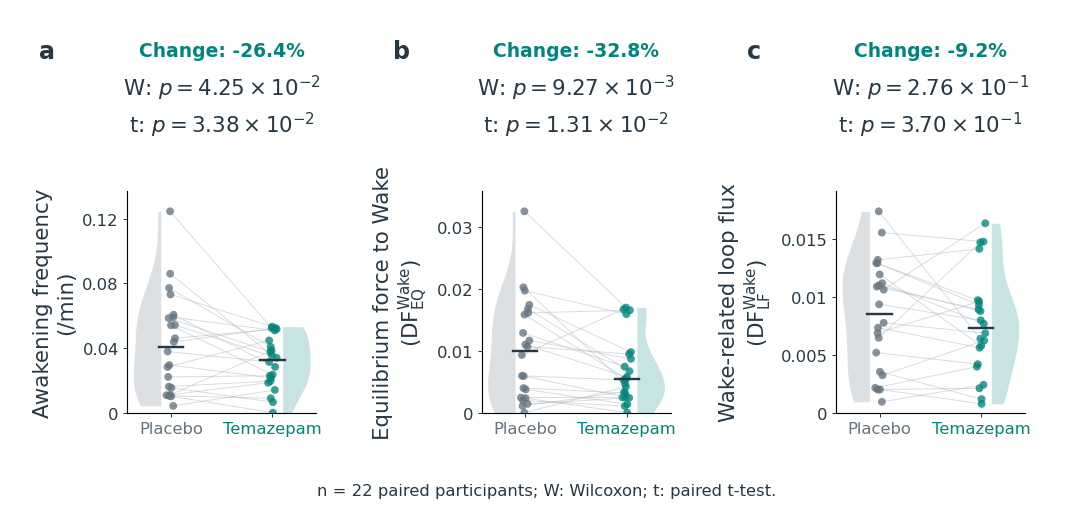

In [15]:
# Global settings: all text sizes and physical canvas dimensions.
FONT_SIZE = 10.0
FIG_WIDTH_MM = 180.0
FIG_HEIGHT_MM = 85.0
OUTPUT_DIR = 'AllFiguresNapNoc_cleaned/Fig5_Temazepam_v8'
BOOTSTRAP_N = 0  # No CI requested; skip bootstrap.
SEED = 1
SHOW_VIOLIN = True
SHOW_CI = False
STRICT_LAYOUT = False  # Remaining layout diagnostics never block normal export.
SHOW_T_TEST = True  # Hides t text only if False; test remains in output table.
SUBJECT_IDS = None  # Optional same-order, unique participant IDs.
AWAKENING_DIVISOR = 60.0  # Retains your original /60 conversion to /min.

_required = ['PlaceboAwakeningFrequency','TemazepamAwakeningFrequency',
             'PlaceboFlux_sym_list','TemazepamFlux_sym_list',
             'PlaceboWakeCycleStrength','TemazepamWakeCycleStrength']
_missing = [name for name in _required if name not in globals()]
if _missing:
    raise NameError('Missing input variables: '+', '.join(_missing))
if not np.isfinite(AWAKENING_DIVISOR) or AWAKENING_DIVISOR <= 0:
    raise ValueError('AWAKENING_DIVISOR must be positive.')

# Manuscript EQ: only non-Wake -> Wake exchange. Matrix audit reports any
# difference from the original full-column sum when self-flow is nonzero.
PlaceboAllSymFluxToWake, _ps = fig5_matrix_summary(
    PlaceboFlux_sym_list,'PlaceboFlux_sym_list','symmetric_to_wake')
TemazepamAllSymFluxToWake, _ts = fig5_matrix_summary(
    TemazepamFlux_sym_list,'TemazepamFlux_sym_list','symmetric_to_wake')

# Each WakeCycleStrength entry is already the total contribution from that
# participant's loops containing Wake. Use exactly once, with no extra weighting.
fig5 = plot_fig5(
    _fig5_vector(PlaceboAwakeningFrequency,'PlaceboAwakeningFrequency')/AWAKENING_DIVISOR,
    _fig5_vector(TemazepamAwakeningFrequency,'TemazepamAwakeningFrequency')/AWAKENING_DIVISOR,
    PlaceboAllSymFluxToWake,TemazepamAllSymFluxToWake,
    PlaceboWakeCycleStrength,TemazepamWakeCycleStrength,
    subject_ids=SUBJECT_IDS,font_size=FONT_SIZE,
    fig_width_mm=FIG_WIDTH_MM,fig_height_mm=FIG_HEIGHT_MM,
    n_boot=BOOTSTRAP_N,random_seed=SEED,show_violin=SHOW_VIOLIN,
    show_ci=SHOW_CI,show_t_test=SHOW_T_TEST,output_dir=OUTPUT_DIR,strict_layout=STRICT_LAYOUT,
    matrix_audit=pd.concat([_ps,_ts],ignore_index=True))

fig_WakeComparison = fig5['figure']
axes_WakeComparison = fig5['axes']
WakeComparisonStatsDF = fig5['statistics']
Fig5SourceData = fig5['source_data']
print('C uses WakeCycleStrength directly: Wake-related loop flux, no extra edge weighting.')
print(WakeComparisonStatsDF[['Metric','N_pairs','Percent_change_from_Placebo','Wilcoxon_p','Paired_t_p']].to_string(index=False))
print('Output:',fig5['paths'])
plt.show()


## 9. Drug k scan and Supplementary Fig. 5

先运行原始 k 扫描一次，得到 `out_drug_k`；仅调整 SI Fig5 样式时重跑后面的绘图 cell 即可。
保留原 k 网格 `np.arange(0,5,0.1)`、双侧配对 Wilcoxon、min_n_pairs=3 及 force 参数。
原扫描函数会同时保存一幅扫描诊断图；最终合并图由最后一个 run cell 输出。


In [16]:
k_values = np.arange(
    0,
    5,
    0.1,
)


out_drug_k = scan_k_temazepam_placebo_differences(

    # ========================================================
    # Temazepam
    # ========================================================
    tema_data=TemazepamHypnograms_dict,

    tema_AllCycle=TemazepamAllCycle,

    tema_AllStrength=TemazepamAllStrength,

    tema_Flux_sym_list=TemazepamFlux_sym_list,

    tema_temporal_cycle_occurrence_df=Temazepam_df_occ,


    # ========================================================
    # Placebo
    # ========================================================
    placebo_data=PlaceboHypnograms_dict,

    placebo_AllCycle=PlaceboAllCycle,

    placebo_AllStrength=PlaceboAllStrength,

    placebo_Flux_sym_list=PlaceboFlux_sym_list,

    placebo_temporal_cycle_occurrence_df=Placebo_df_occ,


    # ========================================================
    # k
    # ========================================================
    k_values=k_values,


    # ========================================================
    # Same force-analysis function as before
    # ========================================================
    analyze_func=(
        analyze_nremrem_loop_flux_plus_sym_force_by_hypnogram
    ),


    # ========================================================
    # Cycle definition
    # ========================================================
    epoch_sec=30,

    wake_state=0,
    rem_state=4,

    nrem_states=(
        1,
        2,
        3,
    ),

    include_post_rem_state=True,

    include_wake_in_structure=True,


    # ========================================================
    # Force settings
    # ========================================================
    min_segment_edges=1,

    allow_loop_reuse=True,

    count_each_loop_once_per_cycle=True,

    sum_unique_missing_edges=True,

    multiply_loop_flux_by_n_edges=True,


    # ========================================================
    # Statistics
    # ========================================================
    min_n_pairs=3,


    # ========================================================
    # Plot
    # ========================================================
    figsize=(10, 7),

    save_path=(
        "AllFiguresNapNoc/Fig5_Temazepam/"
        "Temazepam_vs_Placebo_5metrics_p_vs_k.pdf"
    ),

    verbose=False, #True,
)


# ============================================================
# Main results
# ============================================================

df_drug_stats = out_drug_k[
    "df_stats"
]

df_drug_p_wide = out_drug_k[
    "df_p_wide"
]

df_drug_subject_values = out_drug_k[
    "df_subject_values"
]


/home/datadisk/wxy/Anaconda/envs/lfads-torch/lib/python3.9/site-packages/scipy/stats/_morestats.py:4088: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  warnings.warn("Exact p-value calculation does not work if there are "


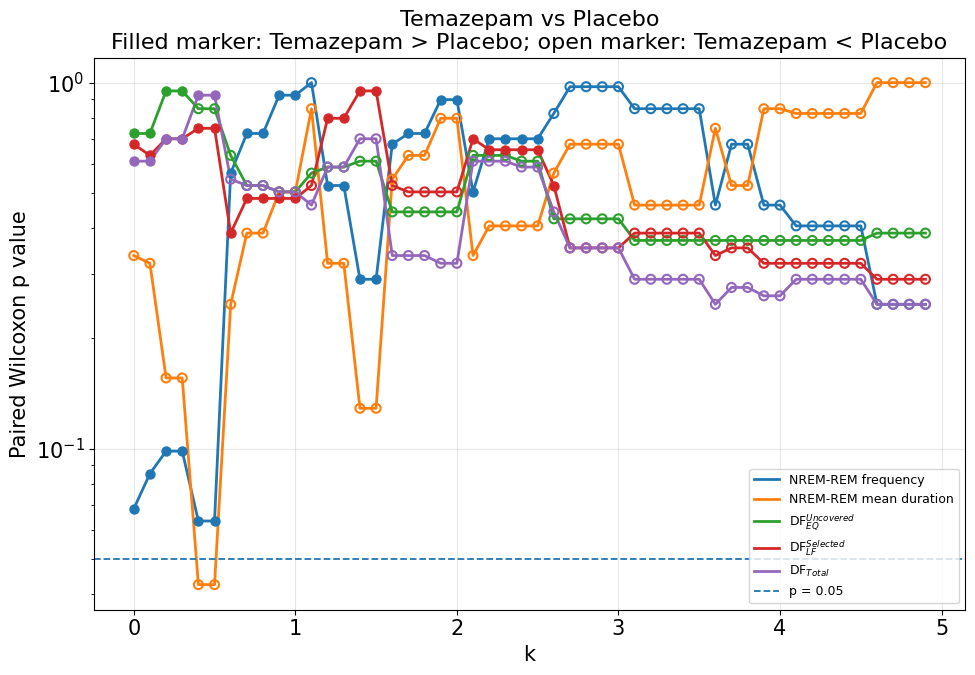

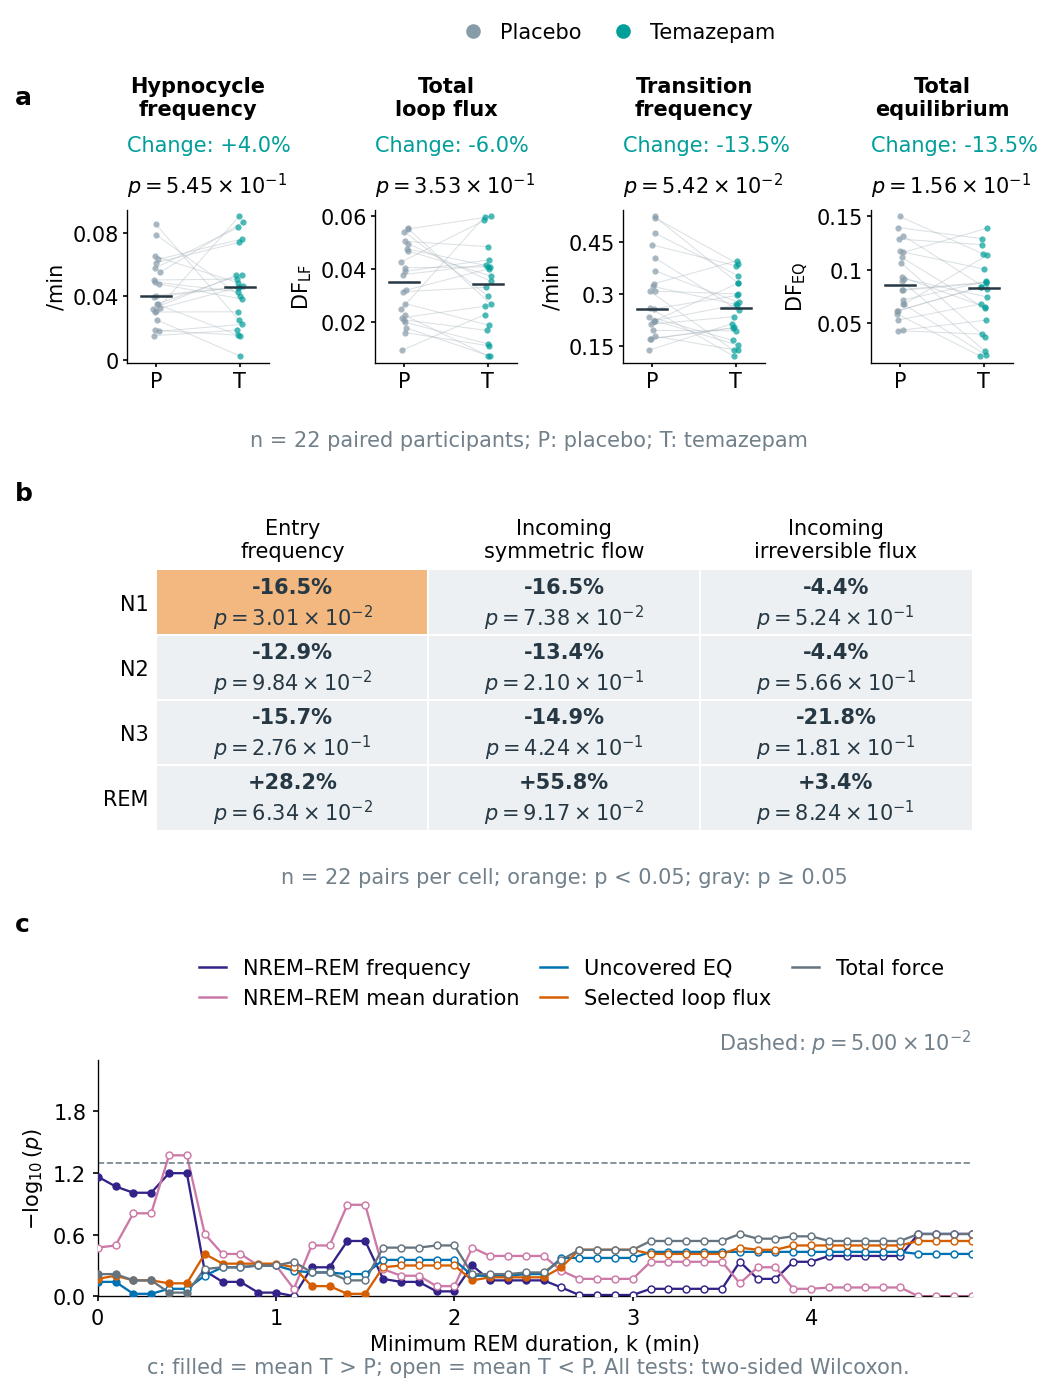

Combined SI drug figure: {'pdf': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Drug_combined_v2/SI_Drug_combined.pdf', 'svg': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Drug_combined_v2/SI_Drug_combined.svg', 'png': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Drug_combined_v2/SI_Drug_combined.png', 'global_statistics': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Drug_combined_v2/SI_Drug_combined_global_statistics.csv', 'stage_statistics': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Drug_combined_v2/SI_Drug_combined_stage_statistics.csv', 'paired_source': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Drug_combined_v2/SI_Drug_combined_paired_source.csv', 'scan_original_statistics': '/home/datadisk1/wxy/lfads-torch/tutorials/SleepStage/AllFiguresNapNoc_cleaned/SI_Drug

In [17]:
# Cell 2: run AFTER your existing out_drug_k scan cell has completed once.
FONT_SIZE=10.0
PANEL_LABEL_SIZE=12.0
FIG_WIDTH_MM=180.0
FIG_HEIGHT_MM=236.0
OUTPUT_DIR='AllFiguresNapNoc_cleaned/SI_Drug_combined_v2'
DPI=600
RANDOM_SEED=1
SIGNIFICANCE_ALPHA=0.05
SIGNIFICANT_COLOR='#F2B880'
NONSIGNIFICANT_COLOR='#EDF0F2'

# Reuse original scan results, never re-run the costly coverage algorithm for styling.
if 'out_drug_k' in globals():
    _drug_scan=out_drug_k
elif 'df_drug_stats' in globals():
    _drug_scan={'df_stats':df_drug_stats,'df_subject_values':globals().get('df_drug_subject_values')}
else:
    raise NameError('Run your scan_k_temazepam_placebo_differences cell first to obtain out_drug_k (or df_drug_stats).')

_required=['PlaceboTST','TemazepamTST','PlaceboTransNum','TemazepamTransNum',
           'Placebo_loop_counts','Temazepam_loop_counts']
_missing=[k for k in _required if k not in globals()]
if _missing:raise NameError('Missing global data: '+', '.join(_missing))

_global={}
for _prefix in ('Placebo','Temazepam'):
    _tst=_sid_vector(globals()[_prefix+'TST'],_prefix+'TST')
    _rates={}
    for _metric,_name in [('transition_frequency','TransNum'),('hypnocycle_frequency','_loop_counts')]:
        _count=_sid_vector(globals()[_prefix+_name],_prefix+_name)
        if len(_count)!=len(_tst):raise ValueError(_prefix+': count/TST lengths differ.')
        _rates[_metric]=np.divide(_count,_tst,out=np.full(len(_count),np.nan),where=np.isfinite(_tst)&(_tst>0))
    _eq=globals().get(_prefix+'AllSymFlux')
    if _eq is None:_eq=_sid_flow_summary(globals()[_prefix+'Flux_sym_list'])['total']
    _lf=globals().get(_prefix+'AllLoopFlux',globals().get(_prefix+'AllIrrFlux'))
    if _lf is None:_lf=_sid_flow_summary(globals()[_prefix+'Flux_irr_list'])['all_entries']
    _global[_prefix]={**_rates,'total_eq':_eq,'total_lf':_lf}
_global_pairs={key:(_global['Placebo'][key],_global['Temazepam'][key]) for key in
               ('hypnocycle_frequency','total_lf','transition_frequency','total_eq')}

# Existing supplied dictionaries take precedence. Otherwise derive the same data.
_stage_freq=globals().get('stage_frequency_data')
if _stage_freq is None:
    _stage_freq={s:(PlaceboSleepMetricsDF[s+'_entry_frequency_per_hour_sleep'].to_numpy(),
                   TemazepamSleepMetricsDF[s+'_entry_frequency_per_hour_sleep'].to_numpy()) for s in ('N1','N2','N3','REM')}
_stage_eq=globals().get('stage_flux_data')
if _stage_eq is None:
    _ep=_sid_flow_summary(PlaceboFlux_sym_list)['incoming'];_et=_sid_flow_summary(TemazepamFlux_sym_list)['incoming']
    _stage_eq={s:(_ep[:,j],_et[:,j]) for j,s in enumerate(('Wake','N1','N2','N3','REM')) if j>0}
_stage_irr=globals().get('stage_irr_flux_data')
if _stage_irr is None:
    _ip=_sid_flow_summary(PlaceboFlux_irr_list)['incoming_all'];_it=_sid_flow_summary(TemazepamFlux_irr_list)['incoming_all']
    _stage_irr={s:(_ip[:,j],_it[:,j]) for j,s in enumerate(('Wake','N1','N2','N3','REM')) if j>0}

si_drug_data=prepare_si_drug(_global_pairs,_stage_freq,_stage_eq,_stage_irr,_drug_scan)
si_drug=plot_si_drug(si_drug_data,font_size=FONT_SIZE,panel_label_size=PANEL_LABEL_SIZE,
    fig_width_mm=FIG_WIDTH_MM,fig_height_mm=FIG_HEIGHT_MM,random_seed=RANDOM_SEED,
    significance_alpha=SIGNIFICANCE_ALPHA,significant_color=SIGNIFICANT_COLOR,nonsignificant_color=NONSIGNIFICANT_COLOR,
    output_dir=OUTPUT_DIR,dpi=DPI,show=True)
print('Combined SI drug figure:',si_drug['paths'])
print(si_drug_data['a_stats'][['metric','n_pairs','change_percent','wilcoxon_p']].to_string(index=False))
print(si_drug_data['b_stats'][['stage','metric','n_pairs','change_percent','wilcoxon_p']].to_string(index=False))